# WIE3007 Individual Assignment
**Qistina Aqilah binti Abdul Razak Tuah (23001946)**  
Domain: Private healthcare (KlinikSihat) | Target: `no_show` | Seed: 001946

In [1]:
# ---------- Setup: seed, libraries, folders, chart style and table helper ----------
SEED = 1946   # matric number 23001946 -> last six digits 001946

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

DATA_DIR = "../data/"
FIG_DIR = "../report/figures/"
os.makedirs(FIG_DIR, exist_ok=True)

# One chart style for every figure in the notebook
sns.set_theme(style="whitegrid", rc={
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Table helper: shows a DataFrame as a clean, styled table with a title
TABLE_STYLE = """
<style>
.table-box {overflow-x: auto; margin: 6px 0 18px 0;}
table.nice {border-collapse: collapse; font-family: Arial, sans-serif; font-size: 13px;}
table.nice caption {caption-side: top; text-align: left !important; white-space: nowrap; font-weight: bold;
                    font-size: 14px; color: #1f3864; background: #ffffff; padding: 6px 8px;}
table.nice th {background: #1f4e79 !important; color: #ffffff !important; padding: 6px 12px;
               text-align: center !important; border: 1px solid #1f4e79;}
table.nice td {background: #ffffff; color: #222222 !important; padding: 5px 12px;
               text-align: center !important; border: 1px solid #d0d7e2;}
table.nice tr:nth-child(even) td {background: #f2f6fb;}
table.nice td:first-child {text-align: left !important; font-weight: bold;}
table.nice.left td {text-align: left !important;}
</style>
"""

def show_table(df, title="", decimals=2, align="center"):
    """Display a DataFrame as a styled table. align="left" left-aligns every cell (for long text)."""
    classes = "nice left" if align == "left" else "nice"
    html = df.to_html(index=False, classes=classes, border=0, na_rep="–",
                      float_format=lambda x: f"{x:,.{decimals}f}")
    if title:
        html = html.replace(">", f"><caption>{title}</caption>", 1)
    display(HTML(TABLE_STYLE + f'<div class="table-box">{html}</div>'))

print(f"✓ Setup complete | seed = {SEED} | pandas {pd.__version__} | numpy {np.__version__}")

✓ Setup complete | seed = 1946 | pandas 3.1.1 | numpy 2.5.4


# Part B — Data Preparation, Quality and Missing Data

## B1. Generate the dataset

**Design.** Each row is one scheduled appointment at a KlinikSihat clinic — the same grain as `fact_appointment` in Part A, flattened (denormalised) so that the dimension attributes (clinic, doctor, patient, channel, date, time slot) sit next to the measures. The target class is **`no_show`** (Yes/No).

**Realistic relationships built in** (through a logistic model of no-show probability):
- longer booking lead time → more no-shows;
- appointments with a reminder (especially two reminders) → fewer no-shows;
- patients with past no-shows → more no-shows;
- younger adults (18–30) and self-pay patients → more no-shows; patients aged 60+ and panel patients → fewer;
- longer distance to the clinic → more no-shows;
- Monday and early-morning (before 10:00) appointments → more no-shows; locum doctors → slightly more.

Other attributes are linked realistically too: older patients book more by phone and younger ones by app; the consultation fee depends on the consultation type and doctor type; health screenings are mostly for older patients.

All randomness comes from `rng`, seeded with `SEED = 1946` (matric 23001946 → last six digits 001946), so the notebook produces exactly the same data on every run.

In [2]:
# ---------- B1.1 Reference data (dimension-like lookups) ----------
N_APPOINTMENTS = 1000          # brief: at least 500 rows
N_PATIENTS     = 700           # some patients have more than one appointment
N_DOCTORS      = 25

clinics = pd.DataFrame({
    "clinic_code": [f"KS{i:02d}" for i in range(1, 11)],
    "clinic_area": ["Petaling Jaya", "Shah Alam", "Subang Jaya", "Klang", "Kajang",
                    "Cheras", "Kepong", "Bangsar", "Putrajaya", "Rawang"],
    "clinic_state": ["Selangor"] * 5 + ["Kuala Lumpur"] * 3 + ["Putrajaya", "Selangor"],
})

doctors = pd.DataFrame({
    "doctor_id": [f"D{i:03d}" for i in range(1, N_DOCTORS + 1)],
    "clinic_code": rng.choice(clinics["clinic_code"], size=N_DOCTORS),
    "doctor_type": rng.choice(["Permanent", "Locum"], size=N_DOCTORS, p=[0.8, 0.2]),
})
# make sure every clinic has at least one doctor
doctors.loc[:9, "clinic_code"] = clinics["clinic_code"].values

# Patients: age drives insurance type, preferred channel and past no-shows
age = np.clip(np.round(rng.gamma(shape=6.0, scale=6.5, size=N_PATIENTS)), 1, 90).astype(int)
insurance = np.where(
    (age >= 22) & (age <= 58),
    rng.choice(["Panel", "Insurance", "Self-pay"], size=N_PATIENTS, p=[0.50, 0.20, 0.30]),
    rng.choice(["Panel", "Insurance", "Self-pay"], size=N_PATIENTS, p=[0.05, 0.25, 0.70]),
)
lam = np.where(age < 30, 0.8, np.where(age < 60, 0.4, 0.2))   # younger patients: more past no-shows
patients = pd.DataFrame({
    "patient_id": [f"P{i:05d}" for i in range(1, N_PATIENTS + 1)],
    "patient_age": age,
    "gender": rng.choice(["F", "M"], size=N_PATIENTS, p=[0.54, 0.46]),
    "insurance_type": insurance,
    "distance_km": np.round(np.clip(rng.lognormal(mean=np.log(6), sigma=0.6, size=N_PATIENTS), 0.5, 45), 1),
    "prior_no_shows_12m": np.minimum(rng.poisson(lam), 5),
})
show_table(pd.DataFrame({"Reference table": ["clinics", "doctors", "patients"],
                         "Rows": [len(clinics), len(doctors), len(patients)],
                         "Columns": [clinics.shape[1], doctors.shape[1], patients.shape[1]]}),
           "Reference data created")
show_table(patients.head(), "First 5 patients", decimals=1)

Reference table,Rows,Columns
clinics,10,3
doctors,25,3
patients,700,6


patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m
P00001,38,M,Panel,7.6,1
P00002,39,F,Panel,1.4,0
P00003,30,F,Self-pay,7.3,0
P00004,36,F,Panel,5.5,1
P00005,38,F,Panel,11.0,0


In [3]:
# ---------- B1.2 Generate the appointments ----------
n = N_APPOINTMENTS
appt = pd.DataFrame({"record_id": np.arange(1, n + 1)})
appt["appointment_no"] = [f"APT-{i:06d}" for i in appt["record_id"]]

# patient and doctor for each appointment
appt["patient_id"] = rng.choice(patients["patient_id"], size=n)
appt["doctor_id"] = rng.choice(doctors["doctor_id"], size=n)
appt = appt.merge(patients, on="patient_id", how="left").merge(doctors, on="doctor_id", how="left")
appt = appt.merge(clinics, on="clinic_code", how="left")

# appointment date: Monday-Saturday, January-June 2026 (clinics closed on Sunday)
all_days = pd.date_range("2026-01-05", "2026-06-27", freq="D")
open_days = all_days[all_days.day_of_week < 6]
appt["appointment_date"] = rng.choice(open_days, size=n)

# booking lead time: about 30% book 0-2 days ahead, the rest further ahead
short = rng.integers(0, 3, size=n)
long_ = np.minimum(np.round(rng.exponential(scale=10, size=n)) + 3, 60).astype(int)
appt["lead_time_days"] = np.where(rng.random(n) < 0.30, short, long_)
appt["booking_date"] = appt["appointment_date"] - pd.to_timedelta(appt["lead_time_days"], unit="D")
appt["day_of_week"] = appt["appointment_date"].dt.day_name()

# time slot: 15-minute slots from 09:00 to 21:45
slots = pd.date_range("09:00", "21:45", freq="15min").strftime("%H:%M")
appt["time_slot"] = rng.choice(slots, size=n)
hour = appt["time_slot"].str[:2].astype(int)
appt["session"] = np.select([hour < 12, hour < 17], ["Morning", "Afternoon"], default="Evening")

# booking channel depends on age: older patients phone, younger use the app
p_young = [0.45, 0.30, 0.15, 0.10]   # App, WhatsApp, Phone, Website
p_mid   = [0.30, 0.35, 0.20, 0.15]
p_old   = [0.10, 0.25, 0.55, 0.10]
channels = ["App", "WhatsApp", "Phone", "Website"]
appt["booking_channel"] = [
    rng.choice(channels, p=(p_young if a < 30 else p_mid if a < 60 else p_old))
    for a in appt["patient_age"]
]

# consultation type depends on age (screenings mostly for older patients)
appt["consultation_type"] = [
    rng.choice(["General", "Follow-up", "Health screening"],
               p=([0.70, 0.25, 0.05] if a < 40 else [0.50, 0.30, 0.20]))
    for a in appt["patient_age"]
]

# reminders: none for same-day bookings; digital channels get more reminders
digital = appt["booking_channel"].isin(["App", "WhatsApp"]).to_numpy()
p_rem = np.where(digital, 0.85, 0.55)
first = (rng.random(n) < p_rem) & (appt["lead_time_days"].to_numpy() >= 1)
second = first & (rng.random(n) < 0.45) & (appt["lead_time_days"].to_numpy() >= 3)
appt["reminders_sent"] = first.astype(int) + second.astype(int)

# consultation fee (RM) depends on consultation type and doctor type, rounded to RM 0.50
base_fee = appt["consultation_type"].map({"General": 45, "Follow-up": 35, "Health screening": 150})
locum_extra = np.where(appt["doctor_type"] == "Locum", 10, 0)
fee = base_fee + locum_extra + rng.normal(0, 5, size=n)
appt["consultation_fee_rm"] = np.round(fee * 2) / 2

# ---------- target: no_show via a logistic model ----------
a = appt["patient_age"].to_numpy()
logit = (
    -2.55
    + 0.060 * np.minimum(appt["lead_time_days"], 30)
    - 0.80 * (appt["reminders_sent"] >= 1)
    - 0.40 * (appt["reminders_sent"] == 2)
    + 0.55 * np.minimum(appt["prior_no_shows_12m"], 3)
    + 0.60 * ((a >= 18) & (a <= 30))
    - 0.50 * (a >= 60)
    + 0.45 * (appt["insurance_type"] == "Self-pay")
    - 0.35 * (appt["insurance_type"] == "Panel")
    + 0.035 * appt["distance_km"]
    + 0.35 * (appt["day_of_week"] == "Monday")
    + 0.40 * (hour < 10)
    + 0.25 * (appt["doctor_type"] == "Locum")
    - 0.60 * (appt["consultation_type"] == "Health screening")
)
p_no_show = 1 / (1 + np.exp(-logit.to_numpy(dtype=float)))
appt["no_show"] = np.where(rng.random(n) < p_no_show, "Yes", "No")

# final column order (dates as ISO strings, as they would be exported from the source system)
cols = ["record_id", "appointment_no", "patient_id", "patient_age", "gender", "insurance_type",
        "distance_km", "prior_no_shows_12m", "clinic_code", "clinic_area", "clinic_state",
        "doctor_id", "doctor_type", "booking_date", "appointment_date", "lead_time_days",
        "day_of_week", "time_slot", "session", "booking_channel", "consultation_type",
        "reminders_sent", "consultation_fee_rm", "no_show"]
ground_truth = appt[cols].copy()
ground_truth["booking_date"] = ground_truth["booking_date"].dt.strftime("%Y-%m-%d")
ground_truth["appointment_date"] = ground_truth["appointment_date"].dt.strftime("%Y-%m-%d")
show_table(ground_truth.head(), f"ground_truth: first 5 of {len(ground_truth)} rows ({ground_truth.shape[1]} columns)",
           decimals=1)

record_id,appointment_no,patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m,clinic_code,clinic_area,clinic_state,doctor_id,doctor_type,booking_date,appointment_date,lead_time_days,day_of_week,time_slot,session,booking_channel,consultation_type,reminders_sent,consultation_fee_rm,no_show
1,APT-000001,P00487,21,F,Self-pay,4.5,0,KS03,Subang Jaya,Selangor,D023,Permanent,2026-01-27,2026-01-27,0,Tuesday,10:30,Morning,Website,General,0,39.5,No
2,APT-000002,P00565,22,F,Panel,6.9,0,KS01,Petaling Jaya,Selangor,D001,Permanent,2026-01-19,2026-01-27,8,Tuesday,19:00,Evening,App,General,2,46.5,No
3,APT-000003,P00257,40,F,Self-pay,10.4,1,KS10,Rawang,Selangor,D018,Permanent,2026-05-01,2026-05-11,10,Monday,14:15,Afternoon,WhatsApp,Follow-up,1,39.5,No
4,APT-000004,P00223,36,F,Panel,8.6,0,KS02,Shah Alam,Selangor,D002,Permanent,2026-04-29,2026-04-29,0,Wednesday,18:30,Evening,App,General,0,37.5,No
5,APT-000005,P00657,62,M,Self-pay,5.9,0,KS03,Subang Jaya,Selangor,D023,Permanent,2026-03-01,2026-03-10,9,Tuesday,14:30,Afternoon,Phone,General,1,53.5,No


In [4]:
# ---------- B1.3 Sanity checks: size, target balance and built-in relationships ----------
gt = ground_truth
numeric = gt.select_dtypes("number").columns.drop("record_id").tolist()
categorical = gt.select_dtypes(exclude="number").columns.drop(["no_show"]).tolist()
show_table(pd.DataFrame({
    "Item": ["Rows", "Attributes (excluding record_id and target)", "Numeric attributes",
             "Categorical attributes", "Target class", "No-show rate"],
    "Value": [len(gt), gt.shape[1] - 2, f"{len(numeric)}: " + ", ".join(numeric),
              f"{len(categorical)}: " + ", ".join(categorical), "no_show (Yes / No)",
              f"{(gt['no_show'] == 'Yes').mean():.1%}"]}), "Dataset summary", align="left")

rate = lambda s: (s == "Yes").mean().round(3)
checks = {
    "lead_time_band": pd.cut(gt["lead_time_days"], [-1, 2, 14, 60], labels=["0-2 days", "3-14 days", "15+ days"]),
    "reminders_sent": gt["reminders_sent"],
    "prior_no_shows_12m": gt["prior_no_shows_12m"].clip(upper=3),
    "insurance_type": gt["insurance_type"],
    "age_band": pd.cut(gt["patient_age"], [0, 17, 30, 59, 90], labels=["0-17", "18-30", "31-59", "60+"]),
}
parts = []
for name, grp in checks.items():
    t = gt.groupby(grp, observed=True)["no_show"].agg(["size", rate]).reset_index()
    t.columns = ["Group", "Appointments", "No-show rate"]
    t.insert(0, "Attribute", name)
    parts.append(t)
pattern = pd.concat(parts, ignore_index=True)
pattern["Group"] = pattern["Group"].astype(str)
pattern["No-show rate"] = (pattern["No-show rate"] * 100).map("{:.1f}%".format)
show_table(pattern, "No-show rate by group (relationships built into the data)")

Item,Value
Rows,1000
Attributes (excluding record_id and target),22
Numeric attributes,"6: patient_age, distance_km, prior_no_shows_12m, lead_time_days, reminders_sent, consultation_fee_rm"
Categorical attributes,"16: appointment_no, patient_id, gender, insurance_type, clinic_code, clinic_area, clinic_state, doctor_id, doctor_type, booking_date, appointment_date, day_of_week, time_slot, session, booking_channel, consultation_type"
Target class,no_show (Yes / No)
No-show rate,16.4%


Attribute,Group,Appointments,No-show rate
lead_time_band,0-2 days,313,14.1%
lead_time_band,3-14 days,462,15.2%
lead_time_band,15+ days,225,22.2%
reminders_sent,0,354,22.6%
reminders_sent,1,394,13.5%
reminders_sent,2,252,12.3%
prior_no_shows_12m,0,626,11.3%
prior_no_shows_12m,1,280,21.1%
prior_no_shows_12m,2,63,34.9%
prior_no_shows_12m,3,31,38.7%


In [5]:
# ---------- B1.4 Save the ground truth (kept untouched for B4 evaluation) ----------
ground_truth.to_csv(DATA_DIR + "ground_truth.csv", index=False)
print(f"✓ Saved {DATA_DIR}ground_truth.csv  ({ground_truth.shape[0]} rows × {ground_truth.shape[1]} columns)")

✓ Saved ../data/ground_truth.csv  (1000 rows × 24 columns)


### Injecting data-quality problems into a copy → `raw.csv`

| Problem | Column(s) | How it is injected | Requirement met |
|---|---|---|---|
| Missing values — **MAR** | `patient_age` | Missing far more often when `booking_channel` = Phone (front-desk staff skip the date of birth) than for other channels; about 8% overall | 5–10% missing; missingness depends on another observed column |
| Missing values — **MCAR** | `consultation_fee_rm` | 7% of rows chosen completely at random (billing interface outage) | 5–10% missing; unrelated to any data |
| Duplicate rows | all | 15 rows copied exactly and appended, then rows shuffled | ≥ 10 duplicates |
| Inconsistent formats | `appointment_date`, `booking_date` | about 20% written as DD/MM/YYYY instead of YYYY-MM-DD | inconsistent date formats |
| | `clinic_state` | mixed case, extra spaces and abbreviations (e.g. `SELANGOR`, ` selangor `, `KL`, `W.P. Kuala Lumpur`) | upper/lower case states |
| | `gender` | `F`/`M` mixed with `Female`/`Male` and lower case | inconsistent categories |
| Out-of-range values | `patient_age` | 4 impossible ages (−3, −1, 150, 212) | ≥ 5 out-of-range values in total (10 here) |
| | `consultation_fee_rm` | 3 fees with the sign flipped (negative) | |
| | `lead_time_days` | 3 negative lead times | |

All injected cells are recorded by `record_id` in `injection_log` so the cleaning in B3 and the evaluation in B4 can be checked against them.

In [6]:
# ---------- B1.5 Inject problems into a copy ----------
raw = ground_truth.copy()
n = len(raw)
injection_log = {}

# (1) MAR missingness in patient_age: depends on booking_channel (Phone much higher)
p_miss_age = np.where(raw["booking_channel"] == "Phone", 0.28, 0.03)
mar_rows = raw.index[rng.random(n) < p_miss_age]
raw.loc[mar_rows, "patient_age"] = np.nan
injection_log["MAR_patient_age"] = raw.loc[mar_rows, "record_id"].tolist()

# (2) MCAR missingness in consultation_fee_rm: 7% of rows completely at random
mcar_rows = raw.index[rng.permutation(n)[: int(round(0.07 * n))]]
raw.loc[mcar_rows, "consultation_fee_rm"] = np.nan
injection_log["MCAR_consultation_fee_rm"] = sorted(raw.loc[mcar_rows, "record_id"].tolist())

# (3) Out-of-range values (chosen only from cells that are not already missing)
ok_age = raw.index[raw["patient_age"].notna()]
age_rows = rng.choice(ok_age, size=4, replace=False)
raw.loc[age_rows, "patient_age"] = [-3, -1, 150, 212]
injection_log["OOR_patient_age"] = sorted(raw.loc[age_rows, "record_id"].tolist())

ok_fee = raw.index[raw["consultation_fee_rm"].notna()]
fee_rows = rng.choice(ok_fee, size=3, replace=False)
raw.loc[fee_rows, "consultation_fee_rm"] = -raw.loc[fee_rows, "consultation_fee_rm"]
injection_log["OOR_consultation_fee_rm"] = sorted(raw.loc[fee_rows, "record_id"].tolist())

lead_rows = rng.choice(raw.index[raw["lead_time_days"] > 0], size=3, replace=False)
raw.loc[lead_rows, "lead_time_days"] = -raw.loc[lead_rows, "lead_time_days"]
injection_log["OOR_lead_time_days"] = sorted(raw.loc[lead_rows, "record_id"].tolist())

# (4) Inconsistent date formats: ~20% of rows written as DD/MM/YYYY
date_rows = raw.index[rng.random(n) < 0.20]
for col in ["appointment_date", "booking_date"]:
    raw.loc[date_rows, col] = pd.to_datetime(raw.loc[date_rows, col]).dt.strftime("%d/%m/%Y")
injection_log["FMT_dates_ddmmyyyy"] = raw.loc[date_rows, "record_id"].tolist()

# (5) Inconsistent state names: case, spaces and abbreviations
variants = {
    "Selangor": ["SELANGOR", "selangor", " Selangor ", "Selangor "],
    "Kuala Lumpur": ["KL", "kuala lumpur", "W.P. Kuala Lumpur", "KUALA LUMPUR"],
    "Putrajaya": ["PUTRAJAYA", "putrajaya", "W.P. Putrajaya"],
}
state_rows = raw.index[rng.random(n) < 0.25]
raw.loc[state_rows, "clinic_state"] = [rng.choice(variants[s]) for s in raw.loc[state_rows, "clinic_state"]]
injection_log["FMT_clinic_state"] = raw.loc[state_rows, "record_id"].tolist()

# (6) Inconsistent gender labels
gender_rows = raw.index[rng.random(n) < 0.15]
gmap = {"F": ["Female", "female", "f"], "M": ["Male", "male", "m"]}
raw.loc[gender_rows, "gender"] = [rng.choice(gmap[g]) for g in raw.loc[gender_rows, "gender"]]
injection_log["FMT_gender"] = raw.loc[gender_rows, "record_id"].tolist()

# (7) Exact duplicate rows: copy 15 rows, append, then shuffle the whole table
dup_src = rng.choice(raw.index, size=15, replace=False)
injection_log["DUP_source_record_ids"] = sorted(raw.loc[dup_src, "record_id"].tolist())
raw = pd.concat([raw, raw.loc[dup_src]], ignore_index=True)
raw = raw.sample(frac=1, random_state=SEED).reset_index(drop=True)
labels = {"MAR_patient_age": "Missing patient_age (MAR)",
          "MCAR_consultation_fee_rm": "Missing consultation_fee_rm (MCAR)",
          "OOR_patient_age": "Impossible patient_age",
          "OOR_consultation_fee_rm": "Negative consultation_fee_rm",
          "OOR_lead_time_days": "Negative lead_time_days",
          "FMT_dates_ddmmyyyy": "Dates written as DD/MM/YYYY",
          "FMT_clinic_state": "Inconsistent clinic_state labels",
          "FMT_gender": "Inconsistent gender labels",
          "DUP_source_record_ids": "Rows copied as exact duplicates"}
show_table(pd.DataFrame({"Injected problem": [labels[k] for k in injection_log],
                         "Records affected": [len(v) for v in injection_log.values()]}),
           f"Injection log (raw has {raw.shape[0]} rows × {raw.shape[1]} columns)")
show_table(raw.head(), "raw: first 5 rows after shuffling", decimals=1)

Injected problem,Records affected
Missing patient_age (MAR),88
Missing consultation_fee_rm (MCAR),70
Impossible patient_age,4
Negative consultation_fee_rm,3
Negative lead_time_days,3
Dates written as DD/MM/YYYY,195
Inconsistent clinic_state labels,252
Inconsistent gender labels,156
Rows copied as exact duplicates,15


record_id,appointment_no,patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m,clinic_code,clinic_area,clinic_state,doctor_id,doctor_type,booking_date,appointment_date,lead_time_days,day_of_week,time_slot,session,booking_channel,consultation_type,reminders_sent,consultation_fee_rm,no_show
588,APT-000588,P00589,40.0,M,Panel,5.8,0,KS01,Petaling Jaya,Selangor,D001,Permanent,2026-02-12,2026-03-12,28,Thursday,16:15,Afternoon,Phone,Follow-up,2,39.0,No
338,APT-000338,P00700,90.0,F,Self-pay,3.7,0,KS04,Klang,Selangor,D004,Permanent,2026-02-13,2026-02-19,6,Thursday,11:00,Morning,WhatsApp,Health screening,0,155.5,No
301,APT-000301,P00456,–,F,Panel,3.8,0,KS02,Shah Alam,Selangor,D002,Permanent,2026-02-11,2026-02-17,6,Tuesday,10:30,Morning,Phone,General,2,48.0,No
459,APT-000459,P00357,32.0,F,Self-pay,3.0,1,KS10,Rawang,Selangor,D018,Permanent,05/02/2026,27/02/2026,22,Friday,10:45,Morning,WhatsApp,General,1,39.5,No
219,APT-000219,P00672,35.0,M,Panel,7.7,0,KS10,Rawang,Selangor,D012,Permanent,2026-06-11,2026-06-12,1,Friday,20:45,Evening,Website,General,1,37.5,No


In [7]:
# ---------- B1.6 Verify every injection meets the brief ----------
base = raw.drop_duplicates()            # the duplicates are exact copies, so drop them for rate checks
n_dup = int(raw.duplicated().sum())
pct_age = base["patient_age"].isna().mean()
pct_fee = base["consultation_fee_rm"].isna().mean()
oor = int(((base["patient_age"] < 0) | (base["patient_age"] > 120)).sum()
          + (base["consultation_fee_rm"] < 0).sum() + (base["lead_time_days"] < 0).sum())
n_ddmm = int(base["appointment_date"].str.contains("/").sum())
ok = lambda cond: "✓ OK" if cond else "✗ CHECK"
show_table(pd.DataFrame({
    "Requirement (brief)": ["At least 500 rows", "MAR missing values, 5-10%", "MCAR missing values, 5-10%",
                            "At least 10 duplicate rows", "Inconsistent date formats",
                            "Inconsistent state labels", "At least 5 out-of-range values"],
    "Column(s)": ["all", "patient_age", "consultation_fee_rm", "all", "appointment_date, booking_date",
                  "clinic_state, gender", "patient_age, consultation_fee_rm, lead_time_days"],
    "Result": [f"{len(ground_truth)} rows (+ {n_dup} duplicates = {len(raw)})",
               f"{base['patient_age'].isna().sum()} rows = {pct_age:.1%}",
               f"{base['consultation_fee_rm'].isna().sum()} rows = {pct_fee:.1%}",
               f"{n_dup} rows", f"{n_ddmm} rows in DD/MM/YYYY",
               f"{base['clinic_state'].nunique()} state spellings, {base['gender'].nunique()} gender labels",
               f"{oor} values"],
    "Status": [ok(len(ground_truth) >= 500), ok(0.05 <= pct_age <= 0.10), ok(0.05 <= pct_fee <= 0.10),
               ok(n_dup >= 10), ok(n_ddmm > 0), ok(base["clinic_state"].nunique() > 3), ok(oor >= 5)]}),
    "Check that every injection meets the brief", align="left")

mar = base.groupby("booking_channel")["patient_age"].agg(["size", lambda s: s.isna().mean() * 100]).reset_index()
mar.columns = ["booking_channel", "Appointments", "patient_age missing (%)"]
show_table(mar, "MAR evidence: missing patient_age by booking channel", decimals=1)

show_table(pd.DataFrame({
    "Column": ["clinic_state", "gender"],
    "Labels in raw.csv": [", ".join(repr(str(v)) for v in sorted(base["clinic_state"].unique())),
                          ", ".join(repr(str(v)) for v in sorted(base["gender"].unique()))]}),
    "Inconsistent labels injected", align="left")

Requirement (brief),Column(s),Result,Status
At least 500 rows,all,1000 rows (+ 15 duplicates = 1015),✓ OK
"MAR missing values, 5-10%",patient_age,88 rows = 8.8%,✓ OK
"MCAR missing values, 5-10%",consultation_fee_rm,70 rows = 7.0%,✓ OK
At least 10 duplicate rows,all,15 rows,✓ OK
Inconsistent date formats,"appointment_date, booking_date",195 rows in DD/MM/YYYY,✓ OK
Inconsistent state labels,"clinic_state, gender","14 state spellings, 8 gender labels",✓ OK
At least 5 out-of-range values,"patient_age, consultation_fee_rm, lead_time_days",10 values,✓ OK


booking_channel,Appointments,patient_age missing (%)
App,360,4.2
Phone,225,27.1
Website,126,2.4
WhatsApp,289,3.1


Column,Labels in raw.csv
clinic_state,"' Selangor ', 'KL', 'KUALA LUMPUR', 'Kuala Lumpur', 'PUTRAJAYA', 'Putrajaya', 'SELANGOR', 'Selangor', 'Selangor ', 'W.P. Kuala Lumpur', 'W.P. Putrajaya', 'kuala lumpur', 'putrajaya', 'selangor'"
gender,"'F', 'Female', 'M', 'Male', 'f', 'female', 'm', 'male'"


In [8]:
# ---------- B1.7 Save raw.csv ----------
raw.to_csv(DATA_DIR + "raw.csv", index=False)
print(f"✓ Saved {DATA_DIR}raw.csv  ({raw.shape[0]} rows × {raw.shape[1]} columns)")

✓ Saved ../data/raw.csv  (1015 rows × 24 columns)


## B2. Profile the data

Profiling is done on **`raw.csv` exactly as received** (before any cleaning), so that it shows the problems B3 must fix. It covers:
1. structure, summary statistics and data-quality checks;
2. a missing-value matrix and a missingness heatmap;
3. a univariate and a bivariate visualisation;
4. statistical tests to classify the missingness of each affected column as MCAR, MAR or MNAR.

Figures are also saved to `report/figures/` for the report.

In [9]:
# ---------- B2.1 Load raw.csv and inspect structure ----------
import missingno as msno
from scipy import stats

raw = pd.read_csv(DATA_DIR + "raw.csv")
overview = pd.DataFrame({
    "Column": raw.columns,
    "Data type": raw.dtypes.astype(str).values,
    "Non-missing": raw.notna().sum().values,
    "Missing": raw.isna().sum().values,
    "Unique values": raw.nunique().values,
})
show_table(overview, f"Structure of raw.csv ({raw.shape[0]} rows × {raw.shape[1]} columns)")

Column,Data type,Non-missing,Missing,Unique values
record_id,int64,1015,0,1000
appointment_no,str,1015,0,1000
patient_id,str,1015,0,547
patient_age,float64,925,90,79
gender,str,1015,0,8
insurance_type,str,1015,0,3
distance_km,float64,1015,0,159
prior_no_shows_12m,int64,1015,0,5
clinic_code,str,1015,0,10
clinic_area,str,1015,0,10


In [10]:
# ---------- B2.2 Summary statistics ----------
num_cols = ["patient_age", "distance_km", "prior_no_shows_12m", "lead_time_days",
            "reminders_sent", "consultation_fee_rm"]
show_table(raw[num_cols].describe().T.reset_index(names="Attribute"), "Summary statistics: numeric attributes")

cat_cols = ["gender", "insurance_type", "clinic_code", "clinic_state", "doctor_type",
            "day_of_week", "session", "booking_channel", "consultation_type", "no_show"]
show_table(raw[cat_cols].describe().T.reset_index(names="Attribute"), "Summary statistics: categorical attributes")

Attribute,count,mean,std,min,25%,50%,75%,max
patient_age,925.00,40.25,17.31,-3.00,28.00,38.00,49.00,212.00
distance_km,"1,015.00",7.34,5.16,1.00,3.80,5.90,8.90,35.70
prior_no_shows_12m,"1,015.00",0.51,0.79,0.00,0.00,0.00,1.00,4.00
lead_time_days,"1,015.00",9.29,9.61,-4.00,2.00,6.00,13.00,60.00
reminders_sent,"1,015.00",0.90,0.77,0.00,0.00,1.00,2.00,2.00
consultation_fee_rm,942.00,55.75,36.01,-51.00,39.00,44.50,51.38,166.00


Attribute,count,unique,top,freq
gender,1015,8,F,458
insurance_type,1015,3,Panel,388
clinic_code,1015,10,KS03,290
clinic_state,1015,14,Selangor,464
doctor_type,1015,2,Permanent,876
day_of_week,1015,6,Monday,190
session,1015,3,Evening,408
booking_channel,1015,4,App,366
consultation_type,1015,3,General,634
no_show,1015,2,No,848


In [11]:
# ---------- B2.3 Data-quality checks that feed into B3 ----------
bad_age = (raw["patient_age"] < 0) | (raw["patient_age"] > 120)
iso = raw["appointment_date"].str.match(r"^\d{4}-\d{2}-\d{2}$")
ddmm = raw["appointment_date"].str.match(r"^\d{2}/\d{2}/\d{4}$")
issues = pd.DataFrame({
    "Check": ["Exact duplicate rows", "Missing patient_age", "Missing consultation_fee_rm",
              "patient_age < 0 or > 120", "consultation_fee_rm < 0", "lead_time_days < 0",
              "appointment_date format", "clinic_state spellings", "gender labels"],
    "Rows": [raw.duplicated().sum(), raw["patient_age"].isna().sum(), raw["consultation_fee_rm"].isna().sum(),
             bad_age.sum(), (raw["consultation_fee_rm"] < 0).sum(), (raw["lead_time_days"] < 0).sum(),
             ddmm.sum(), raw["clinic_state"].nunique(), raw["gender"].nunique()],
    "Details": ["identical copies of other rows",
                f"{raw['patient_age'].isna().mean():.1%} of rows",
                f"{raw['consultation_fee_rm'].isna().mean():.1%} of rows",
                "values: " + ", ".join(f"{v:g}" for v in sorted(raw.loc[bad_age, 'patient_age'].unique())),
                "negative fees", "negative lead times",
                f"{iso.sum()} rows YYYY-MM-DD, {ddmm.sum()} rows DD/MM/YYYY, {(~iso & ~ddmm).sum()} other",
                "distinct labels (should be 3)", "distinct labels (should be 2)"]})
show_table(issues, "Data-quality issues found in raw.csv (input to B3)", align="left")

states = raw["clinic_state"].map(repr).value_counts().reset_index()
states.columns = ["clinic_state label (quotes show spaces)", "Rows"]
show_table(states, "clinic_state labels")
genders = raw["gender"].value_counts().reset_index()
genders.columns = ["gender label", "Rows"]
show_table(genders, "gender labels")

Check,Rows,Details
Exact duplicate rows,15,identical copies of other rows
Missing patient_age,90,8.9% of rows
Missing consultation_fee_rm,73,7.2% of rows
patient_age < 0 or > 120,4,"values: -3, -1, 150, 212"
consultation_fee_rm < 0,3,negative fees
lead_time_days < 0,3,negative lead times
appointment_date format,196,"819 rows YYYY-MM-DD, 196 rows DD/MM/YYYY, 0 other"
clinic_state spellings,14,distinct labels (should be 3)
gender labels,8,distinct labels (should be 2)


clinic_state label (quotes show spaces),Rows
'Selangor',464
'Kuala Lumpur',221
'Putrajaya',76
'Selangor ',46
' Selangor ',45
'SELANGOR',40
'selangor',38
'KUALA LUMPUR',19
'W.P. Kuala Lumpur',17
'KL',15


gender label,Rows
F,458
M,397
female,36
male,33
Female,26
f,25
m,23
Male,17


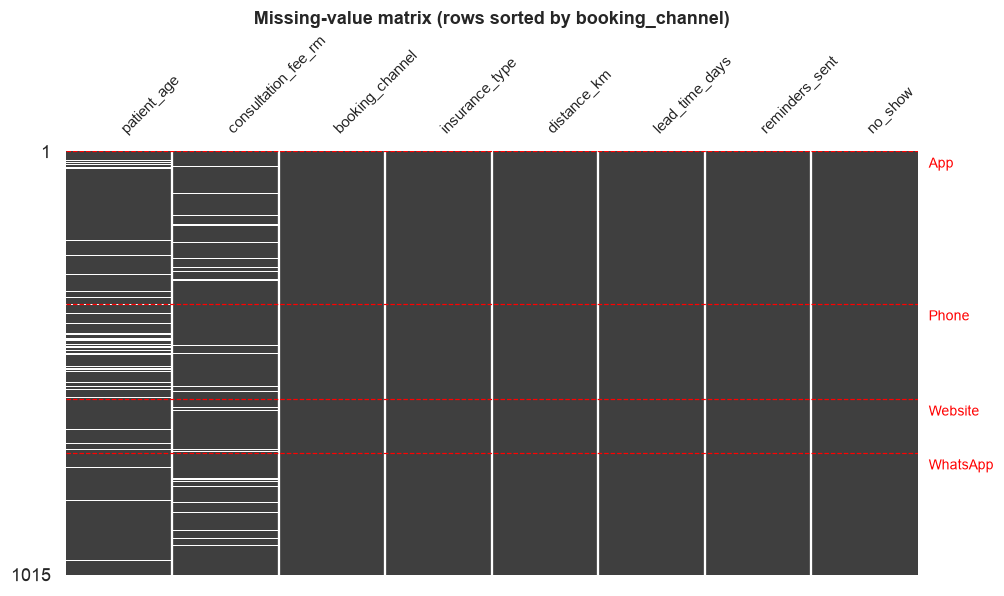

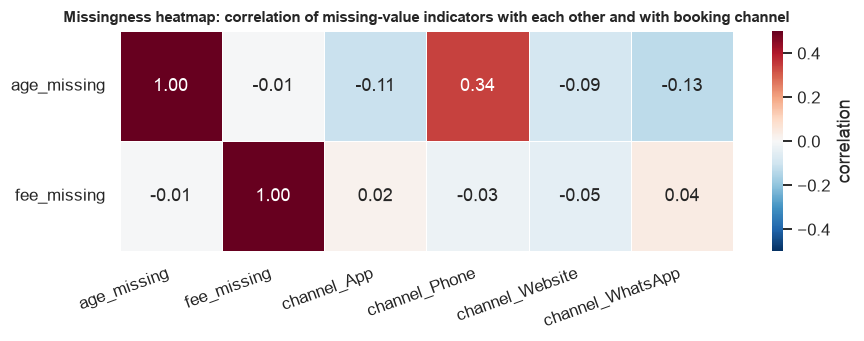

Indicator,age_missing,fee_missing,channel_App,channel_Phone,channel_Website,channel_WhatsApp
age_missing,1.000,-0.006,-0.112,0.340,-0.088,-0.130
fee_missing,-0.006,1.000,0.021,-0.030,-0.049,0.041


In [12]:
# ---------- B2.4 Missing-value matrix and heatmap ----------
# Rows sorted by booking_channel so any link between missingness and channel becomes visible
show_cols = ["patient_age", "consultation_fee_rm", "booking_channel", "insurance_type",
             "distance_km", "lead_time_days", "reminders_sent", "no_show"]
sorted_raw = raw.sort_values("booking_channel").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(sorted_raw[show_cols], ax=ax, sparkline=False, fontsize=10)
starts = sorted_raw.groupby("booking_channel").apply(lambda g: g.index.min(), include_groups=False)
for ch, start in starts.items():
    ax.axhline(start, color="red", lw=0.8, ls="--")
    ax.text(len(show_cols) - 0.4, start + 15, ch, color="red", fontsize=9, va="top")
ax.set_title("Missing-value matrix (rows sorted by booking_channel)", fontsize=12)
plt.savefig(FIG_DIR + "b2_missing_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Heatmap: correlation between the missingness indicators and booking-channel indicators
ind = pd.DataFrame({
    "age_missing": raw["patient_age"].isna().astype(int),
    "fee_missing": raw["consultation_fee_rm"].isna().astype(int),
})
ind = ind.join(pd.get_dummies(raw["booking_channel"], prefix="channel", dtype=int))
corr = ind.corr().loc[["age_missing", "fee_missing"]]
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.5, vmax=0.5, linewidths=0.5,
            cbar_kws={"label": "correlation"}, ax=ax)
ax.set_title("Missingness heatmap: correlation of missing-value indicators with each other and with booking channel",
             fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.savefig(FIG_DIR + "b2_missing_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
show_table(corr.reset_index(names="Indicator"), "Correlation of missingness indicators", decimals=3)

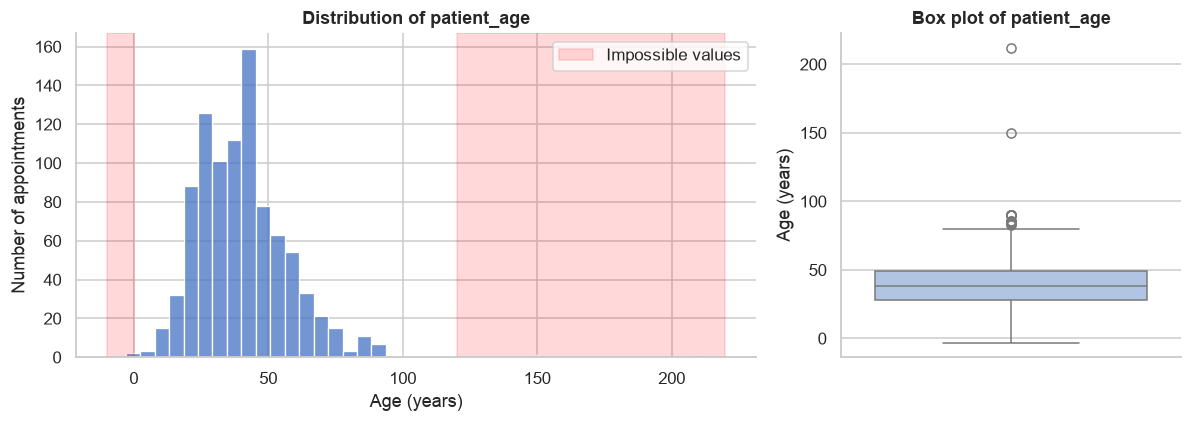

count,mean,std,min,25%,50%,75%,max,skewness
925.00,40.25,17.31,-3.00,28.00,38.00,49.00,212.00,1.79


In [13]:
# ---------- B2.5 Univariate visualisation: patient_age ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(raw["patient_age"].dropna(), bins=40, ax=axes[0], color="#4472c4")
axes[0].axvspan(-10, 0, color="red", alpha=0.15)
axes[0].axvspan(120, 220, color="red", alpha=0.15, label="Impossible values")
axes[0].set(title="Distribution of patient_age", xlabel="Age (years)", ylabel="Number of appointments")
axes[0].legend()
sns.boxplot(y=raw["patient_age"], ax=axes[1], color="#a9c4eb")
axes[1].set(title="Box plot of patient_age", ylabel="Age (years)")
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_univariate_age.png", dpi=150, bbox_inches="tight")
plt.show()
age_stats = raw["patient_age"].describe().to_frame().T
age_stats["skewness"] = raw["patient_age"].skew()
show_table(age_stats, "patient_age: summary statistics (before cleaning)")

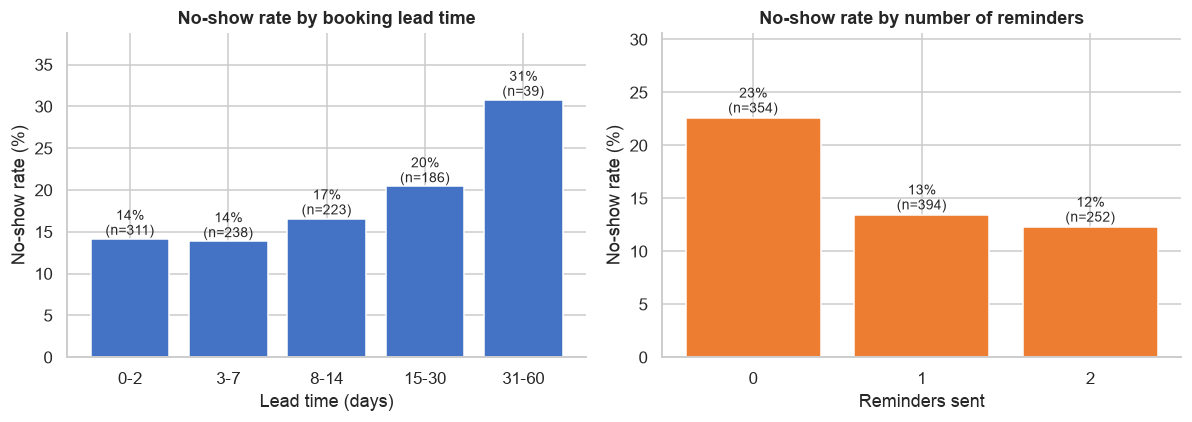

Note: 3 rows with a negative lead time are left out of the lead-time chart.


In [14]:
# ---------- B2.6 Bivariate visualisation: no-show rate vs lead time and reminders ----------
viz = raw.drop_duplicates().copy()
viz["no_show_flag"] = (viz["no_show"] == "Yes").astype(int)
viz["lead_time_band"] = pd.cut(viz["lead_time_days"], [-1, 2, 7, 14, 30, 60],
                               labels=["0-2", "3-7", "8-14", "15-30", "31-60"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lt = viz.groupby("lead_time_band", observed=True)["no_show_flag"].agg(["mean", "size"])
axes[0].bar(lt.index.astype(str), lt["mean"] * 100, color="#4472c4")
for i, (m, s) in enumerate(zip(lt["mean"], lt["size"])):
    axes[0].text(i, m * 100 + 0.5, f"{m:.0%}\n(n={s})", ha="center", fontsize=9)
axes[0].set(title="No-show rate by booking lead time", xlabel="Lead time (days)", ylabel="No-show rate (%)")
axes[0].set_ylim(0, lt["mean"].max() * 100 + 8)

rm = viz.groupby("reminders_sent")["no_show_flag"].agg(["mean", "size"])
axes[1].bar(rm.index.astype(str), rm["mean"] * 100, color="#ed7d31")
for i, (m, s) in enumerate(zip(rm["mean"], rm["size"])):
    axes[1].text(i, m * 100 + 0.5, f"{m:.0%}\n(n={s})", ha="center", fontsize=9)
axes[1].set(title="No-show rate by number of reminders", xlabel="Reminders sent", ylabel="No-show rate (%)")
axes[1].set_ylim(0, rm["mean"].max() * 100 + 8)
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_bivariate_noshow.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Note: {(viz['lead_time_days'] < 0).sum()} rows with a negative lead time are left out of the lead-time chart.")

### Classifying the missingness: MCAR, MAR or MNAR?

For each incomplete column, a missingness indicator (1 = missing, 0 = observed) is tested against every other **observed** column:
- **categorical columns** → chi-square test of independence;
- **numeric columns** → Mann-Whitney U test (compares the distribution in rows where the value is missing vs observed; does not assume normality).

If missingness is unrelated to all observed columns, the data are consistent with **MCAR**. If it depends on one or more observed columns, it is **MAR**. **MNAR** (missingness depending on the unobserved value itself) cannot be tested directly from the observed data, so it is assessed by reasoning plus a within-group check. Tests are run on the de-duplicated data so that the 15 copied rows are not counted twice; out-of-range values are excluded from the numeric comparisons. Because 12 tests are run per column, a Bonferroni-adjusted threshold (0.05 / 12 ≈ 0.0042) is also reported.

In [15]:
# ---------- B2.7 Statistical tests on the missingness indicators ----------
df = raw.drop_duplicates().copy()
valid = {  # mask out impossible values for numeric comparisons
    "patient_age": df["patient_age"].between(0, 120),
    "consultation_fee_rm": df["consultation_fee_rm"] > 0,
    "lead_time_days": df["lead_time_days"] >= 0,
}
cat_test = ["booking_channel", "insurance_type", "consultation_type", "session", "doctor_type",
            "clinic_code", "day_of_week", "no_show"]
num_test = ["patient_age", "distance_km", "prior_no_shows_12m", "lead_time_days",
            "reminders_sent", "consultation_fee_rm"]

def missingness_tests(target):
    miss = df[target].isna()
    rows = []
    for c in cat_test:
        chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], miss))
        rows.append([c, "chi-square", round(chi2, 2), p])
    for c in num_test:
        if c == target:
            continue
        ok = valid.get(c, pd.Series(True, index=df.index)) & df[c].notna()
        if target in valid:                      # also drop rows whose target value is impossible
            ok &= valid[target] | miss
        u, p = stats.mannwhitneyu(df.loc[ok & miss, c], df.loc[ok & ~miss, c])
        rows.append([c, "Mann-Whitney U", round(u, 1), p])
    out = pd.DataFrame(rows, columns=["compared with", "test", "statistic", "p_value"])
    alpha_bonf = 0.05 / len(out)
    out["p_value"] = out["p_value"].map(lambda p: float(f"{p:.3g}"))
    out["significant (0.05)"] = np.where(out["p_value"] < 0.05, "YES", "no")
    out["significant (Bonferroni)"] = np.where(out["p_value"] < alpha_bonf, "YES", "no")
    return out.sort_values("p_value").reset_index(drop=True)

def as_text_p(t):
    """Show p-values in scientific notation so very small values stay readable."""
    t = t.copy()
    t["p_value"] = t["p_value"].map(lambda p: f"{p:.3g}")
    return t

show_table(as_text_p(missingness_tests("patient_age")),
           f"Is missingness in patient_age related to other columns? ({df['patient_age'].isna().sum()} missing)")
show_table(as_text_p(missingness_tests("consultation_fee_rm")),
           f"Is missingness in consultation_fee_rm related to other columns? "
           f"({df['consultation_fee_rm'].isna().sum()} missing)")

compared with,test,statistic,p_value,significant (0.05),significant (Bonferroni)
booking_channel,chi-square,121.74,3.25e-26,YES,YES
reminders_sent,Mann-Whitney U,"31,346.00",0.000366,YES,YES
clinic_code,chi-square,13.06,0.16,no,no
session,chi-square,3.46,0.178,no,no
lead_time_days,Mann-Whitney U,"36,521.00",0.198,no,no
distance_km,Mann-Whitney U,"42,637.00",0.297,no,no
day_of_week,chi-square,5.92,0.314,no,no
consultation_type,chi-square,1.29,0.524,no,no
no_show,chi-square,0.34,0.56,no,no
insurance_type,chi-square,0.68,0.713,no,no


compared with,test,statistic,p_value,significant (0.05),significant (Bonferroni)
prior_no_shows_12m,Mann-Whitney U,"28,966.50",0.0803,no,no
lead_time_days,Mann-Whitney U,"28,790.00",0.125,no,no
session,chi-square,3.29,0.193,no,no
patient_age,Mann-Whitney U,"28,763.50",0.27,no,no
booking_channel,chi-square,3.64,0.303,no,no
clinic_code,chi-square,9.05,0.432,no,no
consultation_type,chi-square,1.43,0.49,no,no
reminders_sent,Mann-Whitney U,"31,418.00",0.637,no,no
doctor_type,chi-square,0.11,0.743,no,no
insurance_type,chi-square,0.58,0.747,no,no


booking_channel,n,patient_age,consultation_fee_rm
App,360,4.2,7.5
Phone,225,27.1,5.8
Website,126,2.4,4.0
WhatsApp,289,3.1,8.7


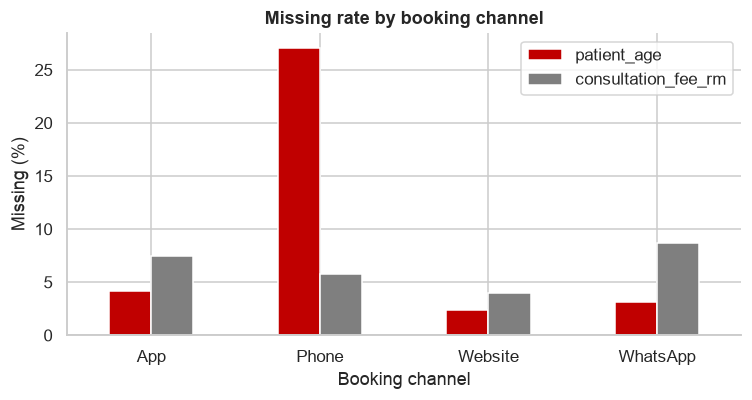

booking_channel,n_missing,distance_km,prior_no_shows_12m,reminders_sent,insurance_type
App,15,0.886,0.169,0.628,0.115
Phone,61,0.209,0.660,0.081,0.858
Website,3,–,–,–,–
WhatsApp,9,0.023,0.322,0.279,0.930


Item,Value
Within-channel tests,12
Bonferroni threshold,0.05 / 12 = 0.0042
Tests with p < 0.05,1
Tests below the Bonferroni threshold,0
Channels skipped,Website (fewer than 5 missing values)


In [16]:
# ---------- B2.8 Follow-up checks ----------
# (a) Missing rate of each column by booking channel
rate_tbl = df.groupby("booking_channel")[["patient_age", "consultation_fee_rm"]] \
             .agg(lambda s: s.isna().mean() * 100).round(1)
rate_tbl.insert(0, "n", df.groupby("booking_channel").size())
show_table(rate_tbl.reset_index(), "Missing rate (%) by booking channel", decimals=1)

fig, ax = plt.subplots(figsize=(7, 3.8))
rate_tbl[["patient_age", "consultation_fee_rm"]].plot.bar(ax=ax, color=["#c00000", "#7f7f7f"], rot=0)
ax.set(title="Missing rate by booking channel", xlabel="Booking channel", ylabel="Missing (%)")
ax.legend(["patient_age", "consultation_fee_rm"])
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_missing_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) Within each channel, is age missingness still related to other observed columns?
#     If MAR given channel, these tests should show no relationship.
res = []
for ch, g in df.groupby("booking_channel"):
    m = g["patient_age"].isna()
    if m.sum() < 5:
        res.append([ch, int(m.sum())] + [np.nan] * 4); continue
    p_dist = stats.mannwhitneyu(g.loc[m, "distance_km"], g.loc[~m, "distance_km"]).pvalue
    p_prior = stats.mannwhitneyu(g.loc[m, "prior_no_shows_12m"], g.loc[~m, "prior_no_shows_12m"]).pvalue
    p_rem = stats.mannwhitneyu(g.loc[m, "reminders_sent"], g.loc[~m, "reminders_sent"]).pvalue
    p_ins = stats.chi2_contingency(pd.crosstab(g["insurance_type"], m))[1]
    res.append([ch, int(m.sum()), round(p_dist, 3), round(p_prior, 3), round(p_rem, 3), round(p_ins, 3)])
within = pd.DataFrame(res, columns=["booking_channel", "n_missing", "distance_km",
                                    "prior_no_shows_12m", "reminders_sent", "insurance_type"])
show_table(within, "Within each channel: p-values for patient_age missingness (Mann-Whitney U / chi-square)",
           decimals=3)
n_tests = int(within.iloc[:, 2:].notna().sum().sum())
show_table(pd.DataFrame({
    "Item": ["Within-channel tests", "Bonferroni threshold", "Tests with p < 0.05",
             "Tests below the Bonferroni threshold", "Channels skipped"],
    "Value": [n_tests, f"0.05 / {n_tests} = {0.05 / n_tests:.4f}",
              int((within.iloc[:, 2:] < 0.05).sum().sum()),
              int((within.iloc[:, 2:] < 0.05 / n_tests).sum().sum()),
              "Website (fewer than 5 missing values)"]}), "Summary of the within-channel check", align="left")

### B2 conclusion

**Missingness classification**

| Column | Missing (de-duplicated data) | Classification | Evidence from profiling |
|---|---|---|---|
| `patient_age` | 88 of 1,000 rows (8.8%) | **MAR** | Missingness depends strongly on the observed column `booking_channel`: Phone 27.1% vs App 4.2%, WhatsApp 3.1%, Website 2.4% (χ² = 121.74, p = 3.3 × 10⁻²⁶; correlation with the Phone indicator = 0.34; clearly visible in the sorted missing-value matrix). It is also related to `reminders_sent` (p = 0.00037), but this is explained by channel: phone bookings receive fewer reminders. **Within each channel**, missingness shows no relationship with distance, prior no-shows, reminders or insurance type (12 tests; 1 below 0.05, none below the Bonferroni threshold), so the dependence is on the channel. |
| `consultation_fee_rm` | 70 of 1,000 rows (7.0%) | **MCAR** | None of the 12 tests is significant, even at 0.05 (smallest p = 0.080). The missing rate is similar in every booking channel (4.0–8.7%), and the nullity correlation with `patient_age` is −0.01. Missingness behaves like a random sample of rows. |

**Why not MNAR?** MNAR means missingness depends on the missing value itself (for example, older patients refusing to give their age, or the most expensive consultations failing to be recorded). This cannot be proven or ruled out from observed data alone, but the evidence points against it:
- *Age:* within the Phone channel, patients with a missing age do not differ from those with a recorded age in insurance type, prior no-shows or reminders, all of which are correlated with age in this dataset. If missingness depended on age itself, these age-related attributes would differ.
- *Fee:* the fee level is driven almost entirely by `consultation_type` (health screenings cost far more). Missingness is unrelated to consultation type (p = 0.49), so expensive consultations are not more likely to be missing.

**Other problems found by profiling (to be fixed in B3)**
- 15 exact duplicate rows.
- Out-of-range values: 4 impossible ages (−3, −1, 150, 212), 3 negative fees, 3 negative lead times.
- Inconsistent formats: 196 rows with DD/MM/YYYY dates (the rest YYYY-MM-DD); 14 different spellings of `clinic_state`; 8 different gender labels.

## B3. Clean and standardise

Every problem found in B2 is fixed in the order below. Each step records how many rows it changed, and these counts fill the data quality log automatically.

1. Remove exact duplicate rows.
2. Standardise the two date columns to `YYYY-MM-DD`.
3. Standardise `clinic_state` and `gender` labels.
4. Fix out-of-range values: negative fees (sign error), negative lead times (recomputed from the dates), impossible ages (set to missing so they are imputed in B4).
5. Record the remaining missing values, which are imputed in B4.

At the end, the cleaned data is compared with `ground_truth.csv` to prove that every fix restored the true value.

In [17]:
# ---------- B3.1 Load raw.csv and remove duplicates ----------
raw = pd.read_csv(DATA_DIR + "raw.csv")
dq_log = []   # one entry per issue: [issue, dimension, detection rule, action, rows affected]

n_dup = int(raw.duplicated().sum())
clean = raw.drop_duplicates(keep="first").sort_values("record_id").reset_index(drop=True)
dq_log.append(["Exact duplicate rows", "Uniqueness", "df.duplicated() is True",
               "Removed the duplicate copies, kept the first occurrence", n_dup])
assert clean["record_id"].is_unique, "record_id should now be unique"
show_table(pd.DataFrame({"Step": ["Rows in raw.csv", "Exact duplicates removed", "Rows after removing duplicates"],
                         "Value": [len(raw), n_dup, len(clean)]}), "B3.1 Duplicates")

Step,Value
Rows in raw.csv,1015
Exact duplicates removed,15
Rows after removing duplicates,1000


In [18]:
# ---------- B3.2 Standardise the date columns ----------
def parse_mixed_dates(s):
    """Parse YYYY-MM-DD and DD/MM/YYYY explicitly (never let pandas guess day vs month)."""
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

date_fixed = clean["appointment_date"].str.contains("/") | clean["booking_date"].str.contains("/")
for col in ["appointment_date", "booking_date"]:
    clean[col] = parse_mixed_dates(clean[col])
    assert clean[col].notna().all(), f"unparsed values in {col}"
dq_log.append(["Mixed date formats in appointment_date and booking_date", "Consistency",
               "value does not match YYYY-MM-DD (contains '/')",
               "Parsed DD/MM/YYYY with an explicit format and rewrote as YYYY-MM-DD", int(date_fixed.sum())])

# consistency check: day_of_week must match the appointment date
dow_mismatch = (clean["appointment_date"].dt.day_name() != clean["day_of_week"]).sum()
show_table(pd.DataFrame({
    "Check": ["Rows with DD/MM/YYYY dates converted", "day_of_week inconsistent with appointment_date",
              "Appointment date range"],
    "Result": [int(date_fixed.sum()), int(dow_mismatch),
               f"{clean['appointment_date'].min().date()} to {clean['appointment_date'].max().date()}"]}),
    "B3.2 Dates")

Check,Result
Rows with DD/MM/YYYY dates converted,195
day_of_week inconsistent with appointment_date,0
Appointment date range,2026-01-05 to 2026-06-27


In [19]:
# ---------- B3.3 Standardise clinic_state and gender ----------
state_map = {"selangor": "Selangor", "kuala lumpur": "Kuala Lumpur", "kl": "Kuala Lumpur",
             "w.p. kuala lumpur": "Kuala Lumpur", "putrajaya": "Putrajaya", "w.p. putrajaya": "Putrajaya"}
new_state = clean["clinic_state"].str.strip().str.lower().map(state_map)
assert new_state.notna().all(), "unmapped state label"
state_changed = int((new_state != clean["clinic_state"]).sum())
clean["clinic_state"] = new_state
dq_log.append(["Inconsistent clinic_state labels (case, spaces, abbreviations)", "Consistency",
               "value not in {Selangor, Kuala Lumpur, Putrajaya}",
               "Trimmed spaces, lower-cased and mapped variants (e.g. KL, W.P. Kuala Lumpur) to the standard name",
               state_changed])

gender_map = {"f": "F", "female": "F", "m": "M", "male": "M"}
new_gender = clean["gender"].str.strip().str.lower().map(gender_map)
assert new_gender.notna().all(), "unmapped gender label"
gender_changed = int((new_gender != clean["gender"]).sum())
clean["gender"] = new_gender
dq_log.append(["Inconsistent gender labels", "Consistency", "value not in {F, M}",
               "Mapped Female/female/f to F and Male/male/m to M", gender_changed])

# cross-check: clinic_state must agree with the clinic's state for every clinic_code
state_per_clinic = clean.groupby("clinic_code")["clinic_state"].nunique()
show_table(pd.DataFrame({
    "Column": ["clinic_state", "gender", "clinic_code vs clinic_state"],
    "Rows changed": [state_changed, gender_changed, "–"],
    "Labels after cleaning": [", ".join(sorted(clean["clinic_state"].unique())),
                              ", ".join(sorted(clean["gender"].unique())),
                              f"{(state_per_clinic > 1).sum()} clinics with more than one state"]}),
    "B3.3 Labels")

Column,Rows changed,Labels after cleaning
clinic_state,252,"Kuala Lumpur, Putrajaya, Selangor"
gender,156,"F, M"
clinic_code vs clinic_state,–,0 clinics with more than one state


In [20]:
# ---------- B3.4 Fix out-of-range values ----------
# (a) negative consultation fees: a sign error, because the absolute values are normal fees
neg_fee = clean["consultation_fee_rm"] < 0
show_table(clean.loc[neg_fee, ["record_id", "consultation_type", "doctor_type", "consultation_fee_rm"]],
           "Negative fees found")
typical = clean.loc[~neg_fee].groupby("consultation_type")["consultation_fee_rm"].agg(["min", "max"])
show_table(typical.reset_index(), "Normal fee range (RM) by consultation type, for comparison")
clean.loc[neg_fee, "consultation_fee_rm"] = clean.loc[neg_fee, "consultation_fee_rm"].abs()
dq_log.append(["Negative consultation_fee_rm", "Validity", "consultation_fee_rm < 0",
               "Sign error: replaced by the absolute value (checked to lie within the normal range for the consultation type)",
               int(neg_fee.sum())])

# (b) negative lead times: recompute from the two dates (the dates are the reliable source)
recomputed = (clean["appointment_date"] - clean["booking_date"]).dt.days
bad_lead = clean["lead_time_days"] != recomputed
lead_before = clean.loc[bad_lead, ["record_id", "lead_time_days"]].assign(recomputed=recomputed[bad_lead])
clean["lead_time_days"] = recomputed
dq_log.append(["Negative lead_time_days", "Validity / Accuracy",
               "lead_time_days < 0, or not equal to appointment_date − booking_date",
               "Recomputed from the two dates", int(bad_lead.sum())])

# (c) impossible ages: no reliable correction, so set to missing and impute in B4
bad_age = (clean["patient_age"] < 0) | (clean["patient_age"] > 120)
age_before = clean.loc[bad_age, ["record_id", "patient_age"]].copy()
clean.loc[bad_age, "patient_age"] = np.nan
dq_log.append(["Impossible patient_age", "Validity", "patient_age < 0 or > 120",
               "Set to missing; imputed in B4", int(bad_age.sum())])

show_table(lead_before.rename(columns={"lead_time_days": "lead_time_days (raw)",
                                       "recomputed": "lead_time_days (from dates)"}),
           "Negative lead times corrected from the dates")
show_table(age_before.rename(columns={"patient_age": "patient_age (raw)"}),
           "Impossible ages set to missing (imputed in B4)", decimals=0)

record_id,consultation_type,doctor_type,consultation_fee_rm
120,General,Permanent,-51.00
625,General,Permanent,-50.50
735,General,Locum,-51.00


consultation_type,min,max
Follow-up,25.50,53.50
General,27.50,66.50
Health screening,138.00,166.00


record_id,lead_time_days (raw),lead_time_days (from dates)
308,-2,2
671,-4,4
777,-1,1


record_id,patient_age (raw)
327,-1
471,212
504,150
639,-3


In [21]:
# ---------- B3.5 Remaining missing values (handled in B4) ----------
miss_age = int(clean["patient_age"].isna().sum())
miss_fee = int(clean["consultation_fee_rm"].isna().sum())
dq_log.append(["Missing patient_age (MAR, depends on booking_channel)", "Completeness", "patient_age is null",
               "Imputed in B4 (includes the 4 impossible ages set to missing in B3.4)", miss_age])
dq_log.append(["Missing consultation_fee_rm (MCAR)", "Completeness", "consultation_fee_rm is null",
               "Imputed in B4", miss_fee])

# store dates as ISO text again, and use whole-number ages
clean["appointment_date"] = clean["appointment_date"].dt.strftime("%Y-%m-%d")
clean["booking_date"] = clean["booking_date"].dt.strftime("%Y-%m-%d")
show_table(pd.DataFrame({"Item": ["Missing patient_age (including the impossible ages)", "Missing consultation_fee_rm",
                                  "Shape after cleaning"],
                         "Value": [miss_age, miss_fee, f"{clean.shape[0]} rows × {clean.shape[1]} columns"]}),
           "B3.5 Left for imputation in B4")

Item,Value
Missing patient_age (including the impossible ages),92
Missing consultation_fee_rm,70
Shape after cleaning,1000 rows × 24 columns


In [22]:
# ---------- B3.6 Data quality log ----------
dq_log_df = pd.DataFrame(dq_log, columns=["Issue", "DQ dimension", "Detection rule", "Action taken", "Rows affected"])
dq_log_df.index = dq_log_df.index + 1
dq_log_df.to_csv("../report/data_quality_log.csv", index_label="#")
show_table(dq_log_df.reset_index(names="#"), "Data quality log", align="left")

#,Issue,DQ dimension,Detection rule,Action taken,Rows affected
1,Exact duplicate rows,Uniqueness,df.duplicated() is True,"Removed the duplicate copies, kept the first occurrence",15
2,Mixed date formats in appointment_date and booking_date,Consistency,value does not match YYYY-MM-DD (contains '/'),Parsed DD/MM/YYYY with an explicit format and rewrote as YYYY-MM-DD,195
3,"Inconsistent clinic_state labels (case, spaces, abbreviations)",Consistency,"value not in {Selangor, Kuala Lumpur, Putrajaya}","Trimmed spaces, lower-cased and mapped variants (e.g. KL, W.P. Kuala Lumpur) to the standard name",252
4,Inconsistent gender labels,Consistency,"value not in {F, M}",Mapped Female/female/f to F and Male/male/m to M,156
5,Negative consultation_fee_rm,Validity,consultation_fee_rm < 0,Sign error: replaced by the absolute value (checked to lie within the normal range for the consultation type),3
6,Negative lead_time_days,Validity / Accuracy,"lead_time_days < 0, or not equal to appointment_date − booking_date",Recomputed from the two dates,3
7,Impossible patient_age,Validity,patient_age < 0 or > 120,Set to missing; imputed in B4,4
8,"Missing patient_age (MAR, depends on booking_channel)",Completeness,patient_age is null,Imputed in B4 (includes the 4 impossible ages set to missing in B3.4),92
9,Missing consultation_fee_rm (MCAR),Completeness,consultation_fee_rm is null,Imputed in B4,70


In [23]:
# ---------- B3.7 Verify the cleaning against ground_truth.csv ----------
gt = pd.read_csv(DATA_DIR + "ground_truth.csv").sort_values("record_id").reset_index(drop=True)
assert (gt["record_id"].values == clean["record_id"].values).all()

checks = []
for col in gt.columns:
    observed = clean[col].notna()
    if pd.api.types.is_numeric_dtype(gt[col]):
        same = np.isclose(clean.loc[observed, col].astype(float), gt.loc[observed, col].astype(float))
    else:
        same = clean.loc[observed, col].astype(str).values == gt.loc[observed, col].astype(str).values
    checks.append([col, int(observed.sum()), int((~same).sum()), int((~observed).sum())])
verify = pd.DataFrame(checks, columns=["column", "values present", "mismatches with ground truth", "still missing"])
verify["status"] = np.where(verify["mismatches with ground truth"] == 0, "✓ matches", "✗ CHECK")
show_table(verify, f"Cleaned data vs ground_truth.csv: "
                   f"{(verify['mismatches with ground truth'] > 0).sum()} columns with mismatches")

column,values present,mismatches with ground truth,still missing,status
record_id,1000,0,0,✓ matches
appointment_no,1000,0,0,✓ matches
patient_id,1000,0,0,✓ matches
patient_age,908,0,92,✓ matches
gender,1000,0,0,✓ matches
insurance_type,1000,0,0,✓ matches
distance_km,1000,0,0,✓ matches
prior_no_shows_12m,1000,0,0,✓ matches
clinic_code,1000,0,0,✓ matches
clinic_area,1000,0,0,✓ matches


## B4. Impute and evaluate

Two incomplete numeric columns remain: `patient_age` (MAR, 92 cells including the 4 impossible ages) and `consultation_fee_rm` (MCAR, 70 cells). Three methods are compared:

| Method | Type | How it works |
|---|---|---|
| **Median** | Simple | Replaces every missing value with the column median (robust to the skew seen in B2). |
| **KNN (k = 5)** | Advanced | Finds the 5 most similar appointments (on standardised features) and averages their values. |
| **MICE (IterativeImputer)** | Advanced | Models each incomplete column as a regression on all other features and iterates until the estimates stabilise. |

The features used to impute are the other attributes: distance, prior no-shows, lead time, reminders, and one-hot encoded insurance type, booking channel, consultation type, doctor type, gender and session. The target `no_show` is **deliberately excluded**, so that the imputation does not leak target information into the C5 model. Because `ground_truth.csv` was kept, each method is scored by **RMSE** (and MAE) computed **only on the cells that were missing**.

In [24]:
# ---------- B4.1 Prepare features and the evaluation mask ----------
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (required to import IterativeImputer)
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

targets = ["patient_age", "consultation_fee_rm"]
num_features = ["distance_km", "prior_no_shows_12m", "lead_time_days", "reminders_sent"]
cat_features = ["insurance_type", "booking_channel", "consultation_type", "doctor_type", "gender", "session"]

X = pd.concat([clean[targets + num_features],
               pd.get_dummies(clean[cat_features], dtype=float)], axis=1).astype(float)
mask = {c: clean[c].isna().to_numpy() for c in targets}
truth = {c: gt[c].to_numpy(dtype=float) for c in targets}
show_table(pd.DataFrame({"Item": ["Feature matrix", "Cells to impute: patient_age",
                                  "Cells to impute: consultation_fee_rm"],
                         "Value": [f"{X.shape[0]} rows × {X.shape[1]} columns", int(mask["patient_age"].sum()),
                                   int(mask["consultation_fee_rm"].sum())]}), "B4.1 Imputation set-up")

Item,Value
Feature matrix,1000 rows × 23 columns
Cells to impute: patient_age,92
Cells to impute: consultation_fee_rm,70


In [25]:
# ---------- B4.2 Run the three imputation methods ----------
def finish(imputed):
    """Return imputed target columns, with ages rounded to whole years as in the source data."""
    out = pd.DataFrame(imputed, columns=X.columns, index=X.index)[targets]
    out["patient_age"] = out["patient_age"].round()
    out["consultation_fee_rm"] = out["consultation_fee_rm"].round(2)
    return out

results = {}
results["Median (simple)"] = finish(SimpleImputer(strategy="median").fit_transform(X))

scaler = StandardScaler()                       # KNN uses distances, so features must be on one scale
X_scaled = scaler.fit_transform(X)              # (StandardScaler ignores NaN when fitting)
knn_scaled = KNNImputer(n_neighbors=5).fit_transform(X_scaled)
results["KNN, k = 5 (advanced)"] = finish(scaler.inverse_transform(knn_scaled))

mice = IterativeImputer(max_iter=20, random_state=SEED)
results["MICE (advanced)"] = finish(mice.fit_transform(X))
print(f"✓ Median, KNN and MICE imputation complete (MICE converged after {mice.n_iter_} iterations)")

✓ Median, KNN and MICE imputation complete (MICE converged after 2 iterations)


In [26]:
# ---------- B4.3 Evaluate against the true values ----------
rows = []
for method, imp in results.items():
    for c in targets:
        y_true, y_pred = truth[c][mask[c]], imp[c].to_numpy()[mask[c]]
        rows.append([method, c, int(mask[c].sum()),
                     np.sqrt(mean_squared_error(y_true, y_pred)), mean_absolute_error(y_true, y_pred)])
evaluation = pd.DataFrame(rows, columns=["method", "column", "cells imputed", "RMSE", "MAE"])
rmse_table = evaluation.pivot(index="method", columns="column", values="RMSE").round(2)
rmse_table = rmse_table.loc[list(results)]
mae_table = evaluation.pivot(index="method", columns="column", values="MAE").loc[list(results)]
scores = pd.DataFrame({"Method": list(results),
                       "RMSE patient_age": rmse_table["patient_age"].values,
                       "MAE patient_age": mae_table["patient_age"].values,
                       "RMSE consultation_fee_rm": rmse_table["consultation_fee_rm"].values,
                       "MAE consultation_fee_rm": mae_table["consultation_fee_rm"].values})
show_table(scores, "Error on the imputed cells, against ground truth (lower is better)")
best = {c: rmse_table[c].idxmin() for c in targets}
print(f"Lowest RMSE: patient_age → {best['patient_age']} | consultation_fee_rm → {best['consultation_fee_rm']}")

# spread check: do the imputed values keep the natural variation of the true values?
spread = []
for c in targets:
    spread.append([c, "True values", truth[c][mask[c]].mean(), truth[c][mask[c]].std()])
    for method, imp in results.items():
        v = imp[c].to_numpy()[mask[c]]
        spread.append([c, method, v.mean(), v.std()])
show_table(pd.DataFrame(spread, columns=["Column", "Values", "Mean", "Std"]),
           "Mean and standard deviation: imputed cells vs true values")

Method,RMSE patient_age,MAE patient_age,RMSE consultation_fee_rm,MAE consultation_fee_rm
Median (simple),19.61,15.71,36.21,17.60
"KNN, k = 5 (advanced)",20.15,15.32,7.47,5.03
MICE (advanced),17.30,13.83,4.75,4.05


Lowest RMSE: patient_age → MICE (advanced) | consultation_fee_rm → MICE (advanced)


Column,Values,Mean,Std
patient_age,True values,43.92,18.70
patient_age,Median (simple),38.00,0.00
patient_age,"KNN, k = 5 (advanced)",45.85,11.83
patient_age,MICE (advanced),44.55,8.97
consultation_fee_rm,True values,55.67,34.44
consultation_fee_rm,Median (simple),44.50,0.00
consultation_fee_rm,"KNN, k = 5 (advanced)",54.08,31.87
consultation_fee_rm,MICE (advanced),55.14,34.27


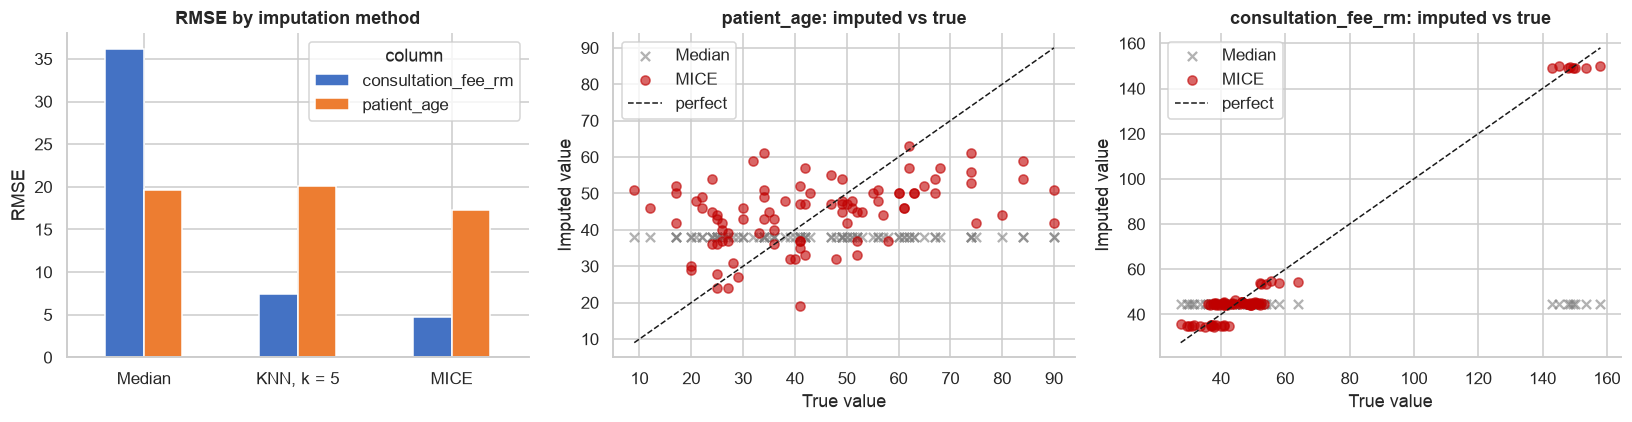

In [27]:
# ---------- B4.4 Visual comparison ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rmse_table.plot.bar(ax=axes[0], rot=0, color=["#4472c4", "#ed7d31"])
axes[0].set(title="RMSE by imputation method", ylabel="RMSE", xlabel="")
axes[0].set_xticklabels([m.split(" (")[0] for m in rmse_table.index])
for c, ax in zip(targets, axes[1:]):
    ax.scatter(truth[c][mask[c]], results["Median (simple)"][c].to_numpy()[mask[c]],
               alpha=0.6, label="Median", marker="x", color="#7f7f7f")
    ax.scatter(truth[c][mask[c]], results[best[c]][c].to_numpy()[mask[c]],
               alpha=0.6, label=best[c].split(" (")[0], color="#c00000")
    lims = [truth[c][mask[c]].min(), truth[c][mask[c]].max()]
    ax.plot(lims, lims, "k--", lw=1, label="perfect")
    ax.set(title=f"{c}: imputed vs true", xlabel="True value", ylabel="Imputed value")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + "b4_imputation_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# ---------- B4.5 Apply the chosen method and save clean.csv ----------
CHOSEN = "MICE (advanced)"
final = clean.copy()
for c in targets:
    final.loc[mask[c], c] = results[CHOSEN].loc[mask[c], c]
final["patient_age"] = final["patient_age"].astype(int)

assert final.isna().sum().sum() == 0, "missing values remain"
assert len(final) == len(gt) and final["record_id"].is_unique
assert final["patient_age"].between(0, 120).all() and (final["consultation_fee_rm"] > 0).all()
final.to_csv(DATA_DIR + "clean.csv", index=False)
show_table(pd.DataFrame({
    "Check": ["File saved", "Imputation method", "Missing values", "Duplicate rows", "Age range",
              "Fee range"],
    "Result": [f"{DATA_DIR}clean.csv ({final.shape[0]} rows × {final.shape[1]} columns)", CHOSEN,
               int(final.isna().sum().sum()), int(final.duplicated().sum()),
               f"{final['patient_age'].min()} to {final['patient_age'].max()} years",
               f"RM {final['consultation_fee_rm'].min():.2f} to RM {final['consultation_fee_rm'].max():.2f}"]}),
    "B4.5 Final clean.csv")

Check,Result
File saved,../data/clean.csv (1000 rows × 24 columns)
Imputation method,MICE (advanced)
Missing values,0
Duplicate rows,0
Age range,6 to 90 years
Fee range,RM 25.50 to RM 166.00


### B4 conclusion: which method to deploy?

| Method | RMSE `patient_age` | RMSE `consultation_fee_rm` |
|---|---|---|
| Median (simple) | 19.61 | 36.21 |
| KNN, k = 5 (advanced) | 20.15 | 7.47 |
| **MICE (advanced)** | **17.30** | **4.75** |

**Deploy MICE (IterativeImputer).** It has the lowest RMSE and MAE for both columns:

- **`consultation_fee_rm`:** MICE cuts the error by about 87% compared with the median (RMSE 4.75 vs 36.21). The fee is almost fully determined by consultation type and doctor type, and MICE learns this relationship, whereas the median gives every missing fee the price of a general consultation, which is badly wrong for health screenings (about RM 150).
- **`patient_age`:** all methods are less accurate because age is only weakly related to the other attributes, but MICE is still best (17.30 vs 19.61 for the median). KNN is slightly *worse* than the median here: with many one-hot features, the 5 "nearest" appointments are often not similar in age.
- **Fits the missingness type:** `patient_age` is MAR (it depends on booking channel). MICE uses booking channel and the other observed attributes as predictors, which is exactly what MAR requires; a single median ignores this information.
- **Practical:** with `random_state = SEED` it is reproducible, and it runs in under a second on 1,000 rows.

**Limitations.** Regression-based imputation pulls values towards the average, so the imputed ages have a smaller spread than the true ages (see the spread table above). This should be remembered when analysing age, for example by keeping a flag for imputed rows. In a real deployment, the better fix for the MAR problem is at the source: make date of birth a required field for phone bookings.

`clean.csv` is saved with the MICE-imputed values: 1,000 rows, no duplicates, no missing values, and every non-imputed value identical to the ground truth.

# Part C — Decision Tree Using ID3

## C1–C3. Check of the hand calculations (ID3 implemented in Python)

The hand calculations for C1–C3 are in the report. This cell re-implements ID3 from scratch (multi-way splits, entropy with log base 2, the brief's tie-break rule) and prints the entropy and information gain at every node, so each hand-calculated value can be checked.

In [29]:
# ---------- C1-C3 check: ID3 from scratch ----------
loan = pd.DataFrame(
    [[1, "High", "Salaried", "Good", "Yes", "Yes"], [2, "High", "Salaried", "Poor", "No", "No"],
     [3, "Medium", "Salaried", "Good", "No", "Yes"], [4, "Low", "Self-employed", "Good", "No", "No"],
     [5, "Low", "Salaried", "Good", "Yes", "Yes"], [6, "Medium", "Self-employed", "Poor", "No", "No"],
     [7, "High", "Self-employed", "Good", "No", "Yes"], [8, "Medium", "Salaried", "Poor", "Yes", "Yes"],
     [9, "Low", "Self-employed", "Poor", "No", "No"], [10, "High", "Salaried", "Good", "No", "Yes"],
     [11, "Medium", "Self-employed", "Good", "Yes", "Yes"], [12, "Low", "Salaried", "Poor", "No", "No"],
     [13, "High", "Self-employed", "Poor", "Yes", "No"], [14, "Medium", "Salaried", "Good", "No", "Yes"]],
    columns=["ID", "Income", "Employment", "Credit History", "Collateral", "Approved"])
ATTRS = ["Income", "Employment", "Credit History", "Collateral"]   # Table C1 order = tie-break order

def entropy(labels):
    p = labels.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum()) + 0.0      # + 0.0 turns -0.0 into 0.0

def id3(data, attrs, depth=0, path="root"):
    pad = "    " * depth
    h = entropy(data["Approved"])
    counts = data["Approved"].value_counts().to_dict()
    print(f"{pad}Node [{path}] records {data['ID'].tolist()} | {counts} | H = {h:.4f}")
    if h == 0 or not attrs:                          # pure (or no attributes left) -> leaf
        label = data["Approved"].mode()[0]
        print(f"{pad}  -> LEAF: {label}")
        return label
    gains = {}
    for a in attrs:
        weighted = sum(len(g) / len(data) * entropy(g["Approved"]) for _, g in data.groupby(a))
        gains[a] = h - weighted
        print(f"{pad}  Gain({a}) = {h:.4f} - {weighted:.4f} = {gains[a]:.4f}")
    best_gain = max(round(g, 10) for g in gains.values())
    tied = [a for a in attrs if round(gains[a], 10) == best_gain]   # attrs are kept in Table C1 order
    best = tied[0]
    note = f"  (tie between {tied}: first in Table C1 is chosen)" if len(tied) > 1 else ""
    print(f"{pad}  => split on {best}{note}")
    remaining = [a for a in attrs if a != best]
    return {best: {v: id3(g, remaining, depth + 1, f"{best} = {v}") for v, g in data.groupby(best)}}

tree_id3 = id3(loan, ATTRS)

def predict_id3(tree, row):
    while isinstance(tree, dict):
        attr = next(iter(tree))
        tree = tree[attr][row[attr]]
    return tree

applicants = pd.DataFrame([["P", "Medium", "Self-employed", "Good", "No"],
                           ["Q", "Low", "Self-employed", "Poor", "Yes"]],
                          columns=["Applicant"] + ATTRS)
applicants["ID3 prediction"] = applicants.apply(lambda r: predict_id3(tree_id3, r), axis=1)
train_acc = (loan.apply(lambda r: predict_id3(tree_id3, r), axis=1) == loan["Approved"]).mean()
print(f"\nTraining accuracy of the ID3 tree: {train_acc:.0%}")
show_table(applicants, "ID3 predictions for Applicants P and Q")

Node [root] records [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | {'Yes': 8, 'No': 6} | H = 0.9852
  Gain(Income) = 0.9852 - 0.8364 = 0.1488
  Gain(Employment) = 0.9852 - 0.8571 = 0.1281
  Gain(Credit History) = 0.9852 - 0.5892 = 0.3960
  Gain(Collateral) = 0.9852 - 0.8950 = 0.0903
  => split on Credit History
    Node [Credit History = Good] records [1, 3, 4, 5, 7, 10, 11, 14] | {'Yes': 7, 'No': 1} | H = 0.5436
      Gain(Income) = 0.5436 - 0.2500 = 0.2936
      Gain(Employment) = 0.5436 - 0.3444 = 0.1992
      Gain(Collateral) = 0.5436 - 0.4512 = 0.0924
      => split on Income
        Node [Income = High] records [1, 7, 10] | {'Yes': 3} | H = 0.0000
          -> LEAF: Yes
        Node [Income = Low] records [4, 5] | {'No': 1, 'Yes': 1} | H = 1.0000
          Gain(Employment) = 1.0000 - 0.0000 = 1.0000
          Gain(Collateral) = 1.0000 - 0.0000 = 1.0000
          => split on Employment  (tie between ['Employment', 'Collateral']: first in Table C1 is chosen)
            Node [Em

Applicant,Income,Employment,Credit History,Collateral,ID3 prediction
P,Medium,Self-employed,Good,No,Yes
Q,Low,Self-employed,Poor,Yes,No


## C4. Verify with code (scikit-learn)

scikit-learn's `DecisionTreeClassifier(criterion="entropy")` is trained on the one-hot-encoded loan data and plotted with `plot_tree`. scikit-learn implements **CART**, which only makes **binary** splits on single (dummy) features, whereas ID3 makes **multi-way** splits on whole attributes.

Item,Value
One-hot features,"Income_High, Income_Low, Income_Medium, Employment_Salaried, Employment_Self-employed, Credit History_Good, Credit History_Poor, Collateral_No, Collateral_Yes"
Tree depth,3
Leaves,6
Training accuracy,100%


Tree as text rules:

|--- Credit History_Good <= 0.50
|   |--- Income_Medium <= 0.50
|   |   |--- class: No
|   |--- Income_Medium >  0.50
|   |   |--- Collateral_Yes <= 0.50
|   |   |   |--- class: No
|   |   |--- Collateral_Yes >  0.50
|   |   |   |--- class: Yes
|--- Credit History_Good >  0.50
|   |--- Income_Low <= 0.50
|   |   |--- class: Yes
|   |--- Income_Low >  0.50
|   |   |--- Collateral_Yes <= 0.50
|   |   |   |--- class: No
|   |   |--- Collateral_Yes >  0.50
|   |   |   |--- class: Yes



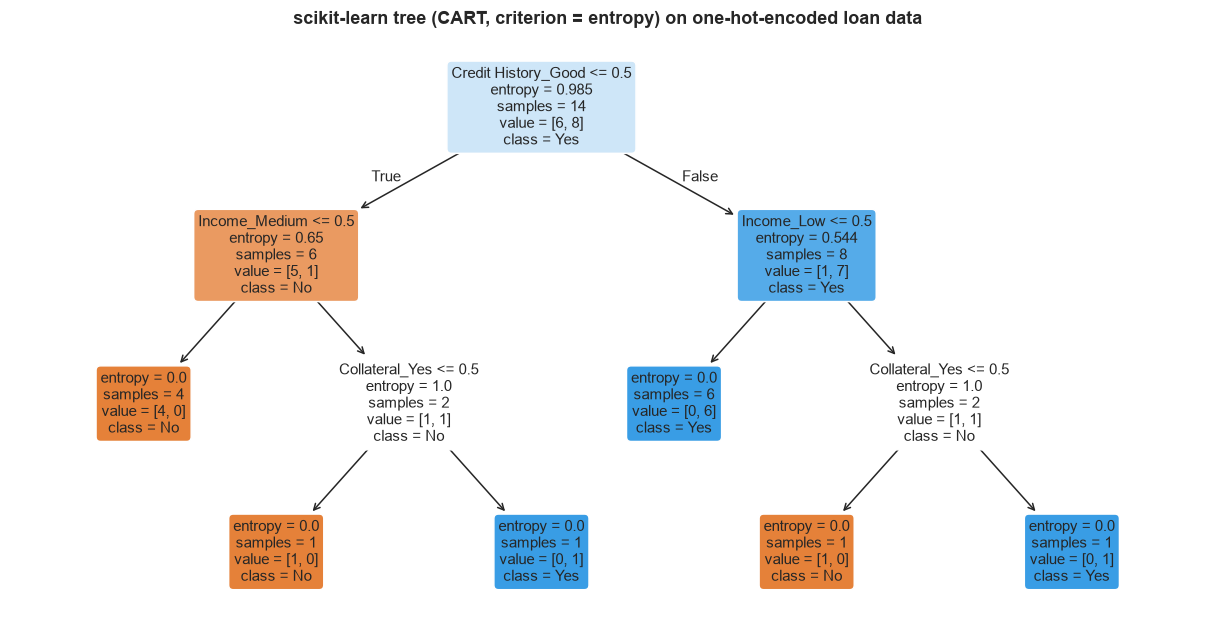

In [30]:
# ---------- C4.1 Train the scikit-learn tree on one-hot-encoded data ----------
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

X_loan = pd.get_dummies(loan[ATTRS], dtype=int)
y_loan = loan["Approved"]
cart = DecisionTreeClassifier(criterion="entropy", random_state=SEED).fit(X_loan, y_loan)

show_table(pd.DataFrame({"Item": ["One-hot features", "Tree depth", "Leaves", "Training accuracy"],
                         "Value": [", ".join(X_loan.columns), cart.get_depth(), cart.get_n_leaves(),
                                   f"{cart.score(X_loan, y_loan):.0%}"]}),
           "scikit-learn tree (random_state = SEED)", align="left")
print("Tree as text rules:\n")
print(export_text(cart, feature_names=X_loan.columns.tolist()))

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(cart, feature_names=X_loan.columns.tolist(), class_names=cart.classes_.tolist(),
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=10, ax=ax)
ax.set_title("scikit-learn tree (CART, criterion = entropy) on one-hot-encoded loan data", fontsize=12)
plt.savefig(FIG_DIR + "c4_sklearn_tree.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
# ---------- C4.2 Root split, predictions for P and Q, and the effect of ties ----------
# information gain of every one-hot feature at the root (binary splits)
h_root = entropy(y_loan)
root_gain = {f: h_root - sum(len(g) / len(loan) * entropy(g) for _, g in y_loan.groupby(X_loan[f]))
             for f in X_loan.columns}
gain_tbl = pd.Series(root_gain).sort_values(ascending=False).reset_index()
gain_tbl.columns = ["Binary split (dummy feature)", "Information gain"]
show_table(gain_tbl, "Information gain of each binary split at the root", decimals=4)

X_new = pd.get_dummies(applicants[ATTRS], dtype=int).reindex(columns=X_loan.columns, fill_value=0)
applicants["CART prediction"] = cart.predict(X_new)
show_table(applicants[["Applicant"] + ATTRS + ["ID3 prediction", "CART prediction"]],
           "Predictions for Applicants P and Q: ID3 vs scikit-learn")

# scikit-learn breaks ties between equally good splits at random (it shuffles the features with
# random_state), so different seeds can give different-looking trees. Check 50 seeds derived
# from my seed (SEED to SEED + 49), so every random_state in the notebook comes from SEED:
structures, preds = {}, {}
for rs in range(SEED, SEED + 50):
    m = DecisionTreeClassifier(criterion="entropy", random_state=rs).fit(X_loan, y_loan)
    structures.setdefault(export_text(m, feature_names=X_loan.columns.tolist()), []).append(rs)
    preds[rs] = tuple(m.predict(X_new))
pq = pd.Series(preds).value_counts()
roots = sorted({s.splitlines()[0].split("<=")[0].strip(" |-") for s in structures})
show_table(pd.DataFrame({
    "Result across 50 random_state values (SEED to SEED + 49)": ["Distinct tree structures", "Root split used"]
        + [f"Predictions P = {t[0]}, Q = {t[1]}" for t in pq.index],
    "Value": [len(structures), " or ".join(roots)] + [f"{n} seeds" for n in pq.values]}),
    "Effect of tie-breaking (random_state) on the scikit-learn tree", align="left")

Binary split (dummy feature),Information gain
Credit History_Good,0.3960
Credit History_Poor,0.3960
Employment_Salaried,0.1281
Employment_Self-employed,0.1281
Income_Low,0.1239
Income_Medium,0.0903
Collateral_No,0.0903
Collateral_Yes,0.0903
Income_High,0.0013


Applicant,Income,Employment,Credit History,Collateral,ID3 prediction,CART prediction
P,Medium,Self-employed,Good,No,Yes,Yes
Q,Low,Self-employed,Poor,Yes,No,No


Result across 50 random_state values (SEED to SEED + 49),Value
Distinct tree structures,39
Root split used,Credit History_Good or Credit History_Poor
"Predictions P = Yes, Q = No",41 seeds
"Predictions P = Yes, Q = Yes",9 seeds


### C4. Where and why the two trees differ

| | ID3 (hand calculation) | scikit-learn (CART), `random_state = 1946` |
|---|---|---|
| Split type | Multi-way: one branch per attribute value | Binary: `feature <= 0.5` on one dummy column |
| Root | Credit History (gain 0.3960) | `Credit History_Good` (gain 0.3960, the same split, because Credit History has only two values) |
| Good branch | Income → High / Medium / **Low → Employment** | `Income_Low`: {High, Medium} → Yes; Low → **`Collateral_Yes`** |
| Poor branch | Income → High / Low / **Medium → Employment** | `Income_Medium`: {High, Low} → No; Medium → **`Collateral_Yes`** |
| Size | Depth 3, 8 leaves | Depth 3, 6 leaves |
| Training accuracy | 100% | 100% |

**1. Binary vs multi-way splits.** ID3 splits Income into three branches. CART can only ask a yes/no question about one dummy column, so it groups values together: in the Good branch it separates Low from {High, Medium}, and in the Poor branch it separates Medium from {High, Low}. The grouped values lead to the same class in the ID3 tree as well (High and Medium are both Yes under Good; High and Low are both No under Poor), so CART needs fewer leaves (6 vs 8) to represent the same decisions.

**2. Ties are broken differently.** At the two-record nodes (Good + Low, and Poor + Medium), Employment and Collateral both give a gain of 1.0000. ID3 uses the brief's rule and picks Employment, the first in Table C1. scikit-learn instead shuffles the features randomly (controlled by `random_state`) and keeps the first best split it finds, so with seed 1946 it picks `Collateral_Yes`. The same happens at the Poor node, where Income and Collateral tie at 0.3167. This is why the 50 seeds tested (1946 to 1995, all derived from `SEED`) produce 39 different-looking trees, although every one of them starts with the Credit History split.

**3. Predictions for P and Q.** With seed 1946 both trees agree: **P = Yes** and **Q = No**. However, the seed experiment shows that Q's prediction is not stable: when CART breaks the tie at the Poor node in favour of Collateral, Q (who has collateral) is classified Yes. Q falls in a region with no training example (Poor credit, Low income, with collateral), so the data alone cannot decide, and the answer depends purely on how the tie is broken. P's prediction (Yes) is the same for every seed.

## C5. Apply to own data

A decision tree is trained on `clean.csv` to predict `no_show`.

- **Features:** the 15 attributes that describe the appointment, patient, clinic and booking (one-hot encoded where categorical). Identifiers (`record_id`, `appointment_no`, `patient_id`, `doctor_id`), the raw dates (already captured by `lead_time_days` and `day_of_week`) and the duplicated location columns (`clinic_area`, `clinic_state`, which add nothing beyond `clinic_code`) are excluded. `time_slot` is converted to `hour_of_day`.
- **Split:** 70% training / 30% test, **stratified** on `no_show`, with `random_state = SEED`.
- **Positive class:** Yes (the patient misses the appointment), because that is what the clinic needs to detect.

In [32]:
# ---------- C5.1 Features, target and stratified 70/30 split ----------
from sklearn.model_selection import train_test_split, cross_validate, RepeatedStratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

data = pd.read_csv(DATA_DIR + "clean.csv")
data["hour_of_day"] = data["time_slot"].str[:2].astype(int)
num_cols_c5 = ["patient_age", "distance_km", "prior_no_shows_12m", "lead_time_days",
               "reminders_sent", "consultation_fee_rm", "hour_of_day"]
cat_cols_c5 = ["gender", "insurance_type", "clinic_code", "doctor_type", "day_of_week",
               "session", "booking_channel", "consultation_type"]
X_c5 = pd.concat([data[num_cols_c5], pd.get_dummies(data[cat_cols_c5], dtype=int)], axis=1)
y_c5 = (data["no_show"] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_c5, y_c5, test_size=0.30, stratify=y_c5, random_state=SEED)
baseline = 1 - y_test.mean()
show_table(pd.DataFrame({"Set": ["Training (70%)", "Test (30%)"],
                         "Rows": [len(X_train), len(X_test)],
                         "No-shows": [int(y_train.sum()), int(y_test.sum())],
                         "No-show rate": [f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"]}),
           f"Stratified split: {X_c5.shape[1]} feature columns from {len(num_cols_c5) + len(cat_cols_c5)} attributes")
print(f"Baseline accuracy (always predict 'No'): {baseline:.1%}")

Set,Rows,No-shows,No-show rate
Training (70%),700,115,16.4%
Test (30%),300,49,16.3%


Baseline accuracy (always predict 'No'): 83.7%


max_depth,train accuracy,CV accuracy (train),test accuracy,test recall (Yes),test predictions = Yes
1,0.836,0.836,0.837,0.000,0
2,0.836,0.832,0.837,0.000,0
3,0.841,0.823,0.830,0.082,10
4,0.857,0.805,0.820,0.082,13
5,0.874,0.802,0.823,0.041,8
6,0.900,0.796,0.820,0.102,15
7,0.926,0.778,0.790,0.184,32
8,0.947,0.777,0.793,0.224,35
9,0.953,0.763,0.777,0.204,38
10,0.974,0.761,0.783,0.245,40


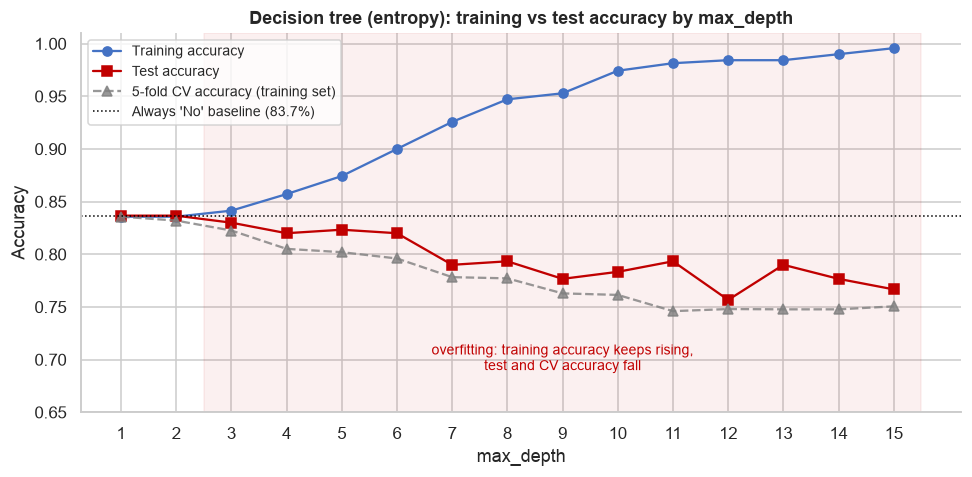

In [33]:
# ---------- C5.2 Training vs test accuracy for max_depth = 1 to 15 ----------
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rows = []
for d in range(1, 16):
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED).fit(X_train, y_train)
    pred = m.predict(X_test)
    cv_acc = cross_validate(DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=SEED),
                            X_train, y_train, cv=cv, scoring="accuracy")["test_score"].mean()
    rows.append([d, m.score(X_train, y_train), cv_acc, accuracy_score(y_test, pred),
                 recall_score(y_test, pred, zero_division=0), int(pred.sum())])
depth_curve = pd.DataFrame(rows, columns=["max_depth", "train accuracy", "CV accuracy (train)",
                                          "test accuracy", "test recall (Yes)", "test predictions = Yes"])
show_table(depth_curve, "Accuracy by max_depth (equal class weights)", decimals=3)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_curve["max_depth"], depth_curve["train accuracy"], "o-", label="Training accuracy", color="#4472c4")
ax.plot(depth_curve["max_depth"], depth_curve["test accuracy"], "s-", label="Test accuracy", color="#c00000")
ax.plot(depth_curve["max_depth"], depth_curve["CV accuracy (train)"], "^--", label="5-fold CV accuracy (training set)",
        color="#7f7f7f", alpha=0.8)
ax.axhline(baseline, color="black", ls=":", lw=1, label=f"Always 'No' baseline ({baseline:.1%})")
ax.axvspan(2.5, 15.5, color="#c00000", alpha=0.06)
ax.text(9, 0.69, "overfitting: training accuracy keeps rising,\ntest and CV accuracy fall",
        ha="center", fontsize=9, color="#c00000")
ax.set(title="Decision tree (entropy): training vs test accuracy by max_depth",
       xlabel="max_depth", ylabel="Accuracy", xticks=range(1, 16), ylim=(0.65, 1.01))
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR + "c5_depth_curve.png", dpi=150, bbox_inches="tight")
plt.show()

max_depth,train F1,CV F1,CV F1 std
1,0.366,0.303,0.052
2,0.399,0.308,0.062
3,0.442,0.311,0.068
4,0.483,0.327,0.065
5,0.539,0.327,0.061
6,0.604,0.327,0.070
7,0.655,0.322,0.076
8,0.737,0.317,0.086
9,0.796,0.310,0.080
10,0.849,0.307,0.091


Chosen max_depth (highest cross-validated F1): 5


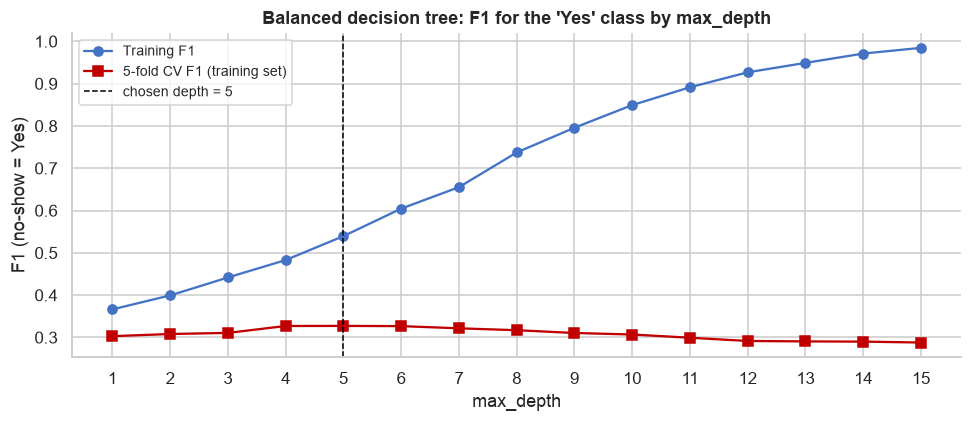

In [34]:
# ---------- C5.3 Choosing the final depth when the classes are imbalanced ----------
# Only 16% of appointments are no-shows. With equal class weights, the depths with the best test
# accuracy (1-2) predict 'No' for everyone (recall = 0), so accuracy alone cannot choose a useful model.
# The final model therefore uses class_weight="balanced", and max_depth is chosen by repeated 5-fold
# cross-validation F1 on the TRAINING set only (the test set is kept untouched for the final evaluation).
rows = []
for d in range(1, 16):
    est = DecisionTreeClassifier(criterion="entropy", max_depth=d, class_weight="balanced", random_state=SEED)
    r = cross_validate(est, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    rows.append([d, r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()])
f1_curve = pd.DataFrame(rows, columns=["max_depth", "train F1", "CV F1", "CV F1 std"])
FINAL_DEPTH = int(f1_curve.loc[f1_curve["CV F1"].idxmax(), "max_depth"])
show_table(f1_curve, "F1 for the 'Yes' class by max_depth (balanced class weights)", decimals=3)
print(f"Chosen max_depth (highest cross-validated F1): {FINAL_DEPTH}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(f1_curve["max_depth"], f1_curve["train F1"], "o-", label="Training F1", color="#4472c4")
ax.plot(f1_curve["max_depth"], f1_curve["CV F1"], "s-", label="5-fold CV F1 (training set)", color="#c00000")
ax.axvline(FINAL_DEPTH, color="black", ls="--", lw=1, label=f"chosen depth = {FINAL_DEPTH}")
ax.set(title="Balanced decision tree: F1 for the 'Yes' class by max_depth", xlabel="max_depth",
       ylabel="F1 (no-show = Yes)", xticks=range(1, 16))
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR + "c5_f1_curve.png", dpi=150, bbox_inches="tight")
plt.show()

Model,accuracy,precision (Yes),recall (Yes),F1 (Yes)
Always 'No' baseline,0.837,0.000,0.000,0.000
"Unweighted tree, depth 2 (best test accuracy)",0.837,0.000,0.000,0.000
"FINAL: balanced tree, depth 5",0.703,0.237,0.367,0.288


Final model ROC AUC on the test set: 0.617


Class,precision,recall,f1-score,support
No (attended),0.862,0.769,0.813,251
Yes (no-show),0.237,0.367,0.288,49
accuracy,–,–,0.703,300
macro avg,0.549,0.568,0.550,300
weighted avg,0.760,0.703,0.727,300


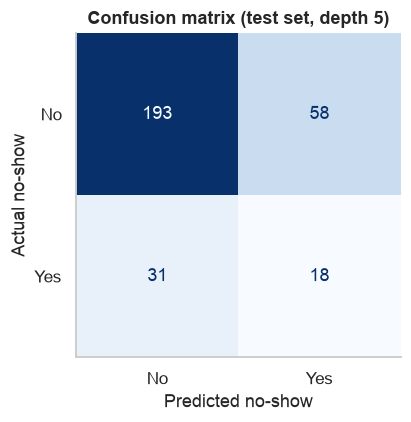

,Predicted No,Predicted Yes
Actual No,TN = 193,FP = 58
Actual Yes,FN = 31,TP = 18


In [35]:
# ---------- C5.4 Final model: evaluation on the test set ----------
final_tree = DecisionTreeClassifier(criterion="entropy", max_depth=FINAL_DEPTH, class_weight="balanced",
                                    random_state=SEED).fit(X_train, y_train)
y_pred = final_tree.predict(X_test)

def metrics(y_true, y_hat):
    return {"accuracy": accuracy_score(y_true, y_hat),
            "precision (Yes)": precision_score(y_true, y_hat, zero_division=0),
            "recall (Yes)": recall_score(y_true, y_hat, zero_division=0),
            "F1 (Yes)": f1_score(y_true, y_hat, zero_division=0)}

simple_tree = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED).fit(X_train, y_train)
comparison = pd.DataFrame({
    "Always 'No' baseline": metrics(y_test, np.zeros_like(y_test)),
    "Unweighted tree, depth 2 (best test accuracy)": metrics(y_test, simple_tree.predict(X_test)),
    f"FINAL: balanced tree, depth {FINAL_DEPTH}": metrics(y_test, y_pred),
}).T
show_table(comparison.reset_index(names="Model"), "Test-set metrics: final model vs simpler alternatives",
           decimals=3)
print(f"Final model ROC AUC on the test set: {roc_auc_score(y_test, final_tree.predict_proba(X_test)[:, 1]):.3f}")

report = pd.DataFrame(classification_report(y_test, y_pred, target_names=["No (attended)", "Yes (no-show)"],
                                            output_dict=True)).T
report.loc["accuracy", ["precision", "recall"]] = np.nan      # accuracy is shown in the f1-score column
report.loc["accuracy", "support"] = len(y_test)
report["support"] = report["support"].astype(int)
show_table(report.reset_index(names="Class"), "Classification report (test set)", decimals=3)

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)   # remove the background grid lines so they do not cross the cells
ax.set(title=f"Confusion matrix (test set, depth {FINAL_DEPTH})", xlabel="Predicted no-show", ylabel="Actual no-show")
plt.tight_layout()
plt.savefig(FIG_DIR + "c5_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
tn, fp, fn, tp = cm.ravel()
show_table(pd.DataFrame({"": ["Actual No", "Actual Yes"], "Predicted No": [f"TN = {tn}", f"FN = {fn}"],
                         "Predicted Yes": [f"FP = {fp}", f"TP = {tp}"]}), "Confusion matrix values")

Feature,Importance
patient_age,0.282
consultation_fee_rm,0.170
lead_time_days,0.155
distance_km,0.105
reminders_sent,0.104
day_of_week_Monday,0.044
clinic_code_KS05,0.040
doctor_type_Locum,0.036


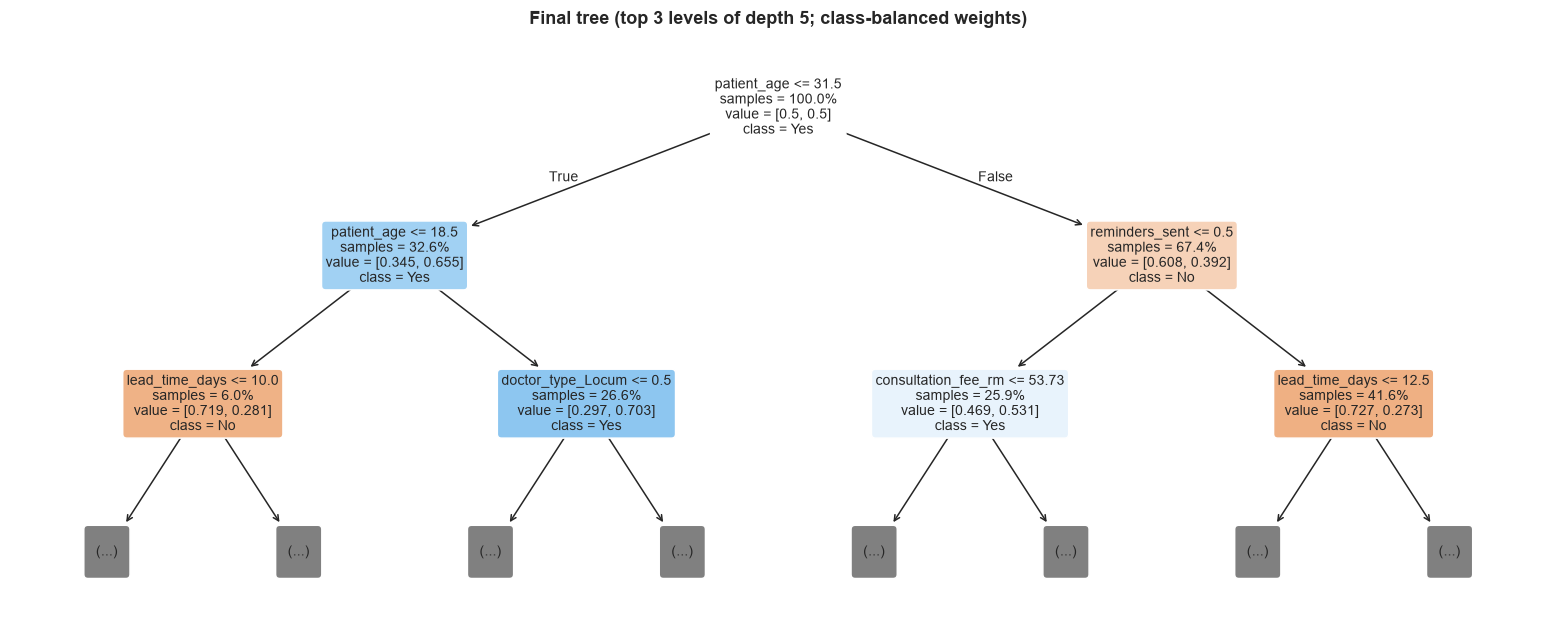

In [36]:
# ---------- C5.5 What the final tree learned ----------
importance = pd.Series(final_tree.feature_importances_, index=X_c5.columns).sort_values(ascending=False)
top8 = importance.head(8).reset_index()
top8.columns = ["Feature", "Importance"]
show_table(top8, "Top 8 features by importance (final tree)", decimals=3)

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(final_tree, feature_names=X_c5.columns.tolist(), class_names=["No", "Yes"], filled=True,
          rounded=True, max_depth=2, fontsize=9, impurity=False, proportion=True, ax=ax)
ax.set_title(f"Final tree (top 3 levels of depth {FINAL_DEPTH}; class-balanced weights)", fontsize=12)
plt.savefig(FIG_DIR + "c5_final_tree_top.png", dpi=150, bbox_inches="tight")
plt.show()

### C5 conclusion

**Stratified split.** 700 training and 300 test appointments; the no-show rate is the same in both (16.4% and 16.3%), so the test set represents the real class balance.

**Where overfitting begins: depth 3.** Training accuracy rises steadily from 83.6% (depth 1) to 99.6% (depth 15) as the tree memorises the training data. Test accuracy and 5-fold cross-validated accuracy are highest at depths 1–2 (83.7%) and **fall from depth 3 onwards** (test accuracy 76.7% and CV accuracy 75.1% at depth 15). The widening gap between training and test accuracy is the classic sign of overfitting.

**Why the final depth is not chosen by accuracy alone.** At depths 1–2 the tree predicts "No" for every appointment: its 83.7% accuracy is exactly the always-"No" baseline, with recall 0 for no-shows. This is the *accuracy paradox* for an imbalanced target (only 16% no-shows). A model that never flags a no-show is useless to the clinic.

**Final choice: `max_depth = 5` with `class_weight = "balanced"`.** Balanced class weights make a missed no-show cost as much as a false alarm. The depth was chosen by repeated 5-fold cross-validated F1 on the training set only, so the test set stayed untouched. CV F1 is highest at depth 5 (0.327). It is essentially level with depths 4 and 6, so the choice between them makes little difference, and it declines after depth 6 while training F1 keeps climbing to 0.985, which is overfitting again.

**Test-set performance of the final model**

| Metric | Value |
|---|---|
| Accuracy | 0.703 |
| Precision (Yes) | 0.237 |
| Recall (Yes) | 0.367 |
| F1 (Yes) | 0.288 |
| ROC AUC | 0.617 |
| Confusion matrix | TN = 193, FP = 58, FN = 31, TP = 18 |

The final model catches 18 of the 49 no-shows (37%) that the accuracy-optimal tree missed completely, at the cost of 58 false alarms. Accuracy is lower than the baseline, but the model is now useful for the business purpose.

**Interpretation.** The tree's first splits are patient age (≤ 31.5 years), reminders sent and lead time, which match the patterns found in B1/B2: young adults, appointments without reminders and long lead times have more no-shows. Overall predictive power is modest (AUC 0.62), as expected for attendance behaviour, which is partly random. In practice the model would be used to prioritise extra reminders or overbooking for high-risk slots, where a false alarm costs only one extra message.

# Part D — Association Rule Mining Using Apriori

## D3. Verify with mlxtend

The 10 breakfast transactions from Table D1 are encoded with `TransactionEncoder`, then `apriori` (minimum support 30%) and `association_rules` are run. The outputs are compared programmatically with the hand results from D1 and D2.

In [37]:
# ---------- D3.1 Frequent itemsets with mlxtend ----------
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

transactions = [
    ["Nasi Lemak", "Teh Tarik", "Roti Canai"],             # T1
    ["Nasi Lemak", "Teh Tarik"],                           # T2
    ["Roti Canai", "Teh Tarik", "Milo"],                   # T3
    ["Nasi Lemak", "Teh Tarik", "Kuih"],                   # T4
    ["Roti Canai", "Milo"],                                # T5
    ["Nasi Lemak", "Kuih"],                                # T6
    ["Nasi Lemak", "Teh Tarik", "Roti Canai", "Kuih"],     # T7
    ["Roti Canai", "Teh Tarik"],                           # T8
    ["Nasi Lemak", "Teh Tarik", "Kuih"],                   # T9
    ["Milo", "Kuih"],                                      # T10
]
MIN_SUPPORT, MIN_CONFIDENCE = 0.30, 0.70

te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_,
                      index=[f"T{i}" for i in range(1, 11)])
show_table(basket.astype(int).reset_index(names="TID"), "One-hot transaction table (1 = item bought)")

frequent = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
frequent["count"] = (frequent["support"] * len(basket)).round().astype(int)
frequent["length"] = frequent["itemsets"].apply(len)
frequent["itemset"] = frequent["itemsets"].apply(lambda s: "{" + ", ".join(sorted(s)) + "}")
frequent = frequent.sort_values(["length", "support"], ascending=[True, False]).reset_index(drop=True)
show_table(frequent[["length", "itemset", "count", "support"]].rename(columns={
               "length": "Size", "itemset": "Itemset", "count": "Support count", "support": "Support"}),
           f"Frequent itemsets from mlxtend (min_support = {MIN_SUPPORT:.0%})")

TID,Kuih,Milo,Nasi Lemak,Roti Canai,Teh Tarik
T1,0,0,1,1,1
T2,0,0,1,0,1
T3,0,1,0,1,1
T4,1,0,1,0,1
T5,0,1,0,1,0
T6,1,0,1,0,0
T7,1,0,1,1,1
T8,0,0,0,1,1
T9,1,0,1,0,1
T10,1,1,0,0,0


Size,Itemset,Support count,Support
1,{Teh Tarik},7,0.70
1,{Nasi Lemak},6,0.60
1,{Kuih},5,0.50
1,{Roti Canai},5,0.50
1,{Milo},3,0.30
2,"{Nasi Lemak, Teh Tarik}",5,0.50
2,"{Kuih, Nasi Lemak}",4,0.40
2,"{Roti Canai, Teh Tarik}",4,0.40
2,"{Kuih, Teh Tarik}",3,0.30
3,"{Kuih, Nasi Lemak, Teh Tarik}",3,0.30


In [38]:
# ---------- D3.2 Compare with the hand results from D1 ----------
hand_frequent = {   # L1, L2 and L3 from the hand calculation: itemset -> support count
    frozenset({"Nasi Lemak"}): 6, frozenset({"Teh Tarik"}): 7, frozenset({"Roti Canai"}): 5,
    frozenset({"Milo"}): 3, frozenset({"Kuih"}): 5,
    frozenset({"Nasi Lemak", "Teh Tarik"}): 5, frozenset({"Nasi Lemak", "Kuih"}): 4,
    frozenset({"Teh Tarik", "Roti Canai"}): 4, frozenset({"Teh Tarik", "Kuih"}): 3,
    frozenset({"Nasi Lemak", "Teh Tarik", "Kuih"}): 3,
}
mlx_frequent = dict(zip(frequent["itemsets"], frequent["count"]))
tick = lambda b: "✓ Yes" if b else "✗ No"
show_table(pd.DataFrame({
    "Check": ["Number of frequent itemsets", "Same itemsets and same support counts",
              "Milo kept at exactly 30% support"],
    "Hand (D1)": [len(hand_frequent), "–", "Yes"],
    "mlxtend": [len(mlx_frequent), tick(mlx_frequent == hand_frequent), tick(frozenset({"Milo"}) in mlx_frequent)]}),
    "D1 check: hand calculation vs mlxtend")

Check,Hand (D1),mlxtend
Number of frequent itemsets,10,10
Same itemsets and same support counts,–,✓ Yes
Milo kept at exactly 30% support,Yes,✓ Yes


In [39]:
# ---------- D3.3 All association rules, compared with the hand results from D2 ----------
rules = association_rules(frequent[["support", "itemsets"]], metric="confidence", min_threshold=0.0)
fmt = lambda s: "{" + ", ".join(sorted(s)) + "}"
rules["rule"] = rules["antecedents"].apply(fmt) + " → " + rules["consequents"].apply(fmt)
rules["meets 70%"] = np.where(rules["confidence"] >= MIN_CONFIDENCE - 1e-12, "YES", "no")
rules = rules.sort_values(["confidence", "lift"], ascending=False).reset_index(drop=True)
show_table(rules[["rule", "support", "confidence", "lift", "meets 70%"]].rename(columns={
               "rule": "Rule", "support": "Support", "confidence": "Confidence", "lift": "Lift",
               "meets 70%": "Meets 70%"}),
           f"All {len(rules)} association rules from frequent itemsets of size ≥ 2", decimals=4)

hand_rules = {  # (antecedent, consequent): (support, confidence, lift) from the hand calculation
    ("Nasi Lemak", "Teh Tarik"): (0.5, 0.8333, 1.1905), ("Teh Tarik", "Nasi Lemak"): (0.5, 0.7143, 1.1905),
    ("Nasi Lemak", "Kuih"): (0.4, 0.6667, 1.3333), ("Kuih", "Nasi Lemak"): (0.4, 0.8000, 1.3333),
    ("Teh Tarik", "Roti Canai"): (0.4, 0.5714, 1.1429), ("Roti Canai", "Teh Tarik"): (0.4, 0.8000, 1.1429),
    ("Teh Tarik", "Kuih"): (0.3, 0.4286, 0.8571), ("Kuih", "Teh Tarik"): (0.3, 0.6000, 0.8571),
    ("Nasi Lemak", "Kuih|Teh Tarik"): (0.3, 0.5000, 1.6667), ("Teh Tarik", "Kuih|Nasi Lemak"): (0.3, 0.4286, 1.0714),
    ("Kuih", "Nasi Lemak|Teh Tarik"): (0.3, 0.6000, 1.2000), ("Nasi Lemak|Teh Tarik", "Kuih"): (0.3, 0.6000, 1.2000),
    ("Kuih|Nasi Lemak", "Teh Tarik"): (0.3, 0.7500, 1.0714), ("Kuih|Teh Tarik", "Nasi Lemak"): (0.3, 1.0000, 1.6667),
}
key = lambda s: "|".join(sorted(s))
mlx_rules = {(key(a), key(c)): (round(s, 4), round(cf, 4), round(l, 4))
             for a, c, s, cf, l in rules[["antecedents", "consequents", "support", "confidence", "lift"]].values}
strong = rules[rules["meets 70%"] == "YES"]
show_table(pd.DataFrame({
    "Check": ["Number of rules", "Same rules with the same support, confidence and lift (4 d.p.)",
              "Rules meeting the 70% minimum confidence"],
    "Hand (D2)": [len(hand_rules), "–", 6],
    "mlxtend": [len(mlx_rules), tick(mlx_rules == hand_rules), len(strong)]}),
    "D2 check: hand calculation vs mlxtend")

Rule,Support,Confidence,Lift,Meets 70%
"{Kuih, Teh Tarik} → {Nasi Lemak}",0.3000,1.0000,1.6667,YES
{Nasi Lemak} → {Teh Tarik},0.5000,0.8333,1.1905,YES
{Kuih} → {Nasi Lemak},0.4000,0.8000,1.3333,YES
{Roti Canai} → {Teh Tarik},0.4000,0.8000,1.1429,YES
"{Kuih, Nasi Lemak} → {Teh Tarik}",0.3000,0.7500,1.0714,YES
{Teh Tarik} → {Nasi Lemak},0.5000,0.7143,1.1905,YES
{Nasi Lemak} → {Kuih},0.4000,0.6667,1.3333,no
"{Nasi Lemak, Teh Tarik} → {Kuih}",0.3000,0.6000,1.2000,no
"{Kuih} → {Nasi Lemak, Teh Tarik}",0.3000,0.6000,1.2000,no
{Kuih} → {Teh Tarik},0.3000,0.6000,0.8571,no


Check,Hand (D2),mlxtend
Number of rules,14,14
"Same rules with the same support, confidence and lift (4 d.p.)",–,✓ Yes
Rules meeting the 70% minimum confidence,6,6


Rule,Support,Confidence,Support of consequent (baseline),Lift
"{Kuih, Teh Tarik} → {Nasi Lemak}",0.3000,1.0000,0.6000,1.6667
{Nasi Lemak} → {Teh Tarik},0.5000,0.8333,0.7000,1.1905
{Kuih} → {Nasi Lemak},0.4000,0.8000,0.6000,1.3333
{Roti Canai} → {Teh Tarik},0.4000,0.8000,0.7000,1.1429
"{Kuih, Nasi Lemak} → {Teh Tarik}",0.3000,0.7500,0.7000,1.0714
{Teh Tarik} → {Nasi Lemak},0.5000,0.7143,0.6000,1.1905


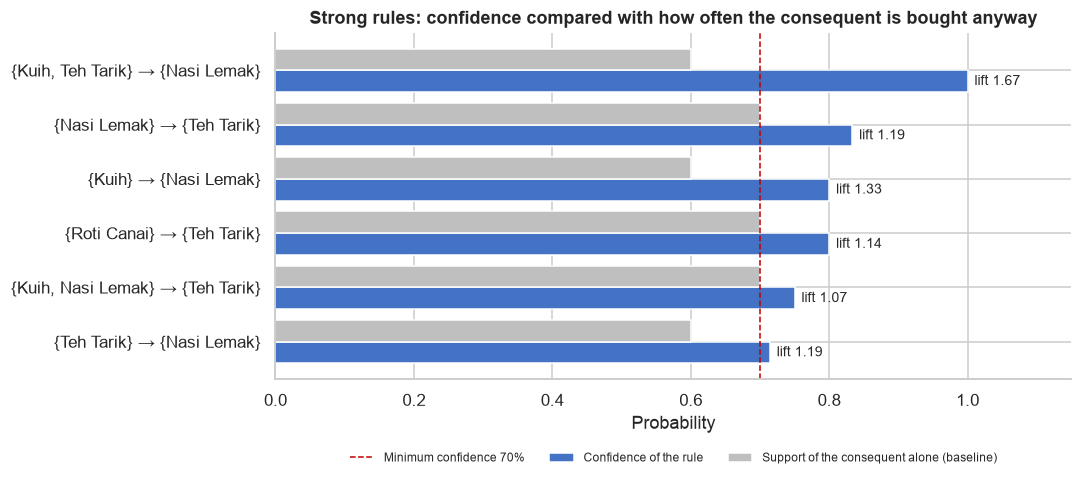

In [40]:
# ---------- D3.4 Strong rules: confidence vs how common the consequent already is ----------
strong = strong.assign(**{"P(consequent)": strong["consequent support"]})
show_table(strong[["rule", "support", "confidence", "P(consequent)", "lift"]].rename(columns={
               "rule": "Rule", "support": "Support", "confidence": "Confidence",
               "P(consequent)": "Support of consequent (baseline)", "lift": "Lift"}),
           "Strong rules: confidence compared with the baseline", decimals=4)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(strong))
ax.barh(y + 0.2, strong["confidence"], height=0.4, label="Confidence of the rule", color="#4472c4")
ax.barh(y - 0.2, strong["P(consequent)"], height=0.4, label="Support of the consequent alone (baseline)",
        color="#bfbfbf")
for i, (c, l) in enumerate(zip(strong["confidence"], strong["lift"])):
    ax.text(c + 0.01, i + 0.2, f"lift {l:.2f}", va="center", fontsize=9)
ax.set_yticks(y, strong["rule"])
ax.invert_yaxis()
ax.axvline(MIN_CONFIDENCE, color="#c00000", ls="--", lw=1, label="Minimum confidence 70%")
ax.set(xlim=(0, 1.15), xlabel="Probability",
       title="Strong rules: confidence compared with how often the consequent is bought anyway")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR + "d3_confidence_vs_lift.png", dpi=150, bbox_inches="tight")
plt.show()

### D3. Interpretation

**Verification.** mlxtend returns exactly the same 10 frequent itemsets (L1–L3) with the same support counts as the hand calculation, including Milo at exactly 30%. It also returns the same 14 rules with identical support, confidence and lift (to 4 d.p.), and the same 6 rules meet the 70% minimum confidence.

**Two strongest rules turned into business actions**

| Rule | Support | Confidence | Lift | Business action |
|---|---|---|---|---|
| {Kuih, Teh Tarik} → {Nasi Lemak} | 0.30 | 1.00 | 1.67 | **Breakfast set bundle.** Every customer who bought kuih and teh tarik also bought nasi lemak. Offer a "Set Pagi" (nasi lemak + teh tarik + kuih) at a small discount compared with buying the three separately, and train counter staff to suggest it. Because these customers already buy all three items, the bundle mainly speeds up ordering and encourages customers who buy only two of the items to add the third. |
| {Kuih} → {Nasi Lemak} | 0.40 | 0.80 | 1.33 | **Menu placement and cross-selling.** 80% of kuih buyers also take nasi lemak, 33% more than the average customer. Display the kuih tray next to the nasi lemak counter, list kuih as an add-on on the nasi lemak section of the menu, and prepare enough nasi lemak on days when kuih stock is high. |

These two rules are chosen because they have the **highest lift** among the rules that meet the minimum confidence, so they show the strongest real association, not just popular items.

**Why high confidence can still be misleading: {Kuih, Nasi Lemak} → {Teh Tarik}**

This rule meets the threshold with **75% confidence**, which looks strong. But Teh Tarik is in **70% of all transactions**, so a randomly chosen customer already has a 70% chance of buying it. Knowing that the customer bought kuih and nasi lemak only raises this from 70% to 75%. The lift shows this directly:

lift = confidence / support(Teh Tarik) = 0.75 / 0.70 = **1.07**

A lift close to 1 means the antecedent and consequent are almost **independent**. The rule mostly reflects that teh tarik is popular, not that kuih and nasi lemak buyers have a special preference for it. A promotion built on this rule would mostly reward customers for something they would do anyway. The same pattern appears in the rule list for {Kuih} → {Teh Tarik} (lift 0.86, below 1): kuih buyers are slightly *less* likely than average to order teh tarik.

**How lift helps.** Confidence only measures P(consequent | antecedent), so it is inflated whenever the consequent is common. Lift compares that confidence with the baseline P(consequent): lift > 1 is a positive association, lift ≈ 1 means independence, and lift < 1 is a negative association. Ranking rules by lift (after the confidence filter) puts {Kuih, Teh Tarik} → {Nasi Lemak} (lift 1.67) at the top and exposes {Kuih, Nasi Lemak} → {Teh Tarik} (lift 1.07) as uninteresting, even though both pass the 70% confidence threshold.